<a href="https://colab.research.google.com/github/Beto1973/nyc-yellow-taxi-data-quality-ml/blob/main/TPI_Machine_Learning_Proyecto_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Selección del dataset

### Origen
Los datos provienen de la **NYC Taxi & Limousine Commission (TLC)** y corresponden a registros de Yellow Taxi publicados mensualmente en formato Parquet.

### Alcance
Se utilizan los archivos de **enero a julio de 2026**:

- **yellow_tripdata_2026-01.parquet**
- **yellow_tripdata_2026-02.parquet**
- **yellow_tripdata_2026-03.parquet**
- **yellow_tripdata_2026-04.parquet**
- **yellow_tripdata_2026-05.parquet**
- **yellow_tripdata_2026-06.parquet**
- **yellow_tripdata_2026-07.parquet**

### Justificación
La elección se fundamenta en que se trata de datos operacionales reales, con variables temporales, geográficas, categóricas y numéricas. Esto permite aplicar las etapas solicitadas de exploración, detección de faltantes, duplicados, outliers y transformación antes de avanzar a la etapa del proyecto final propiamente.

### Pregunta Objetivo
**¿Podemos estimar el importe de la tarifa base (fare_amount) de un viaje a partir de sus características disponibles al momento del viaje?**

## NYC Yellow Taxi Trip Records 2026

**Objetivo de esta etapa:** preparar un dataset real de viajes de Yellow Taxi de NYC para una futura etapa de Machine Learning, aplicando EDA, limpieza, transformación, selección de variables y división entrenamiento/prueba.

### Problema propuesto
Predecir posteriormente el **`fare_amount`** (importe de la tarifa base del viaje) a partir de características conocidas del viaje, evitando variables que contengan información derivada de la propia tarifa y, por tanto, puedan producir *data leakage*.

In [ ]:
# ============================================================
# 2. Configuración e importación de librerías
# ============================================================

# Si aparece un error relacionado con Parquet, ejecutar la siguiente
# línea y reiniciar el entorno:
# !pip -q install pyarrow

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
# Compatibilidad preventiva para entornos locales con Python >= 3.14 y Matplotlib < 3.10
import sys, copy, matplotlib, matplotlib.path as _mpath
if sys.version_info >= (3, 14) and tuple(map(int, matplotlib.__version__.split(".")[:2])) < (3, 10):
    _mpath.Path.__deepcopy__ = lambda self, memo: _mpath.Path(
        copy.deepcopy(self.vertices, memo), copy.deepcopy(self.codes, memo),
        self._interpolation_steps, self._should_simplify, self.simplify_threshold
    )


In [ ]:
# ============================================================
# 3.1 Carga directa de los archivos Parquet
# ============================================================

import os
import glob

print("=" * 70)
print("CARGA DE LOS ARCHIVOS NYC YELLOW TAXI 2026")
print("=" * 70)

# Si los 7 archivos ya se encuentran en el directorio local de trabajo, se utilizan directamente;
# en caso contrario (por ejemplo en Google Colab), se habilita la carga mediante files.upload().
local_candidates = sorted(glob.glob("yellow_tripdata_2026-*.parquet"))

if len(local_candidates) == 7:
    DATA_DIR = os.path.abspath(".")
    files_parquet = local_candidates
    print("\nArchivos detectados en el directorio local de trabajo.")
else:
    from google.colab import files

    # Carpeta de trabajo en Colab
    DATA_DIR = "/content/NYC_Taxi_2026"
    os.makedirs(DATA_DIR, exist_ok=True)

    print("""
Seleccioná los 7 archivos Parquet desde tu computadora:

  yellow_tripdata_2026-01.parquet
  yellow_tripdata_2026-02.parquet
  yellow_tripdata_2026-03.parquet
  yellow_tripdata_2026-04.parquet
  yellow_tripdata_2026-05.parquet
  yellow_tripdata_2026-06.parquet
  yellow_tripdata_2026-07.parquet

Podés seleccionar los 7 archivos simultáneamente.
""")

    uploaded = files.upload()

    # Guardar los archivos en nuestra carpeta de trabajo
    for filename, data in uploaded.items():
        if filename.endswith(".parquet") and filename.startswith("yellow_tripdata_2026-"):
            filepath = os.path.join(DATA_DIR, filename)
            with open(filepath, "wb") as f:
                f.write(data)
            print(f"✓ {filename}")

    # Buscar archivos cargados
    files_parquet = sorted(
        glob.glob(
            os.path.join(DATA_DIR, "yellow_tripdata_2026-*.parquet")
        )
    )

print("\n" + "=" * 70)
print("VERIFICACIÓN")
print("=" * 70)

print(f"\nArchivos encontrados: {len(files_parquet)}\n")

for f in files_parquet:
    size_mb = os.path.getsize(f) / (1024 ** 2)
    print(
        f"{os.path.basename(f):40s} "
        f"{size_mb:8.1f} MB"
    )

# Validación
assert len(files_parquet) == 7, (
    f"Se encontraron {len(files_parquet)} archivos. "
    "Se esperaban exactamente 7 archivos."
)

# Variable que utilizará el resto del notebook
files = files_parquet

print("\n" + "=" * 70)
print("✓ LOS 7 ARCHIVOS FUERON CARGADOS CORRECTAMENTE")
print("=" * 70)

CARGA DE LOS ARCHIVOS NYC YELLOW TAXI 2026

Archivos detectados en el directorio local de trabajo.

VERIFICACIÓN

Archivos encontrados: 7

yellow_tripdata_2026-01.parquet              61.2 MB
yellow_tripdata_2026-02.parquet              56.0 MB
yellow_tripdata_2026-03.parquet              64.7 MB
yellow_tripdata_2026-04.parquet              61.8 MB
yellow_tripdata_2026-05.parquet              66.5 MB
yellow_tripdata_2026-06.parquet              62.4 MB
yellow_tripdata_2026-07.parquet              58.8 MB

✓ LOS 7 ARCHIVOS FUERON CARGADOS CORRECTAMENTE


## Estrategia de memoria

Los siete archivos pueden representar un volumen importante una vez descomprimidos. Por eso:

1. Primero se inspeccionan individualmente.
2. Para el EDA se utiliza una muestra reproducible de cada mes.
3. El dataset analítico se construye con una muestra global controlada si el volumen completo excede la memoria disponible en Colab.

Esto es preferible a cargar indiscriminadamente cientos de millones de valores en memoria.


In [ ]:
# ============================================================
# 3.2 Inspección individual de los archivos
# ============================================================

monthly_info = []

for f in files:
    df_tmp = pd.read_parquet(f, engine="pyarrow")
    monthly_info.append({
        "archivo": os.path.basename(f),
        "filas": len(df_tmp),
        "columnas": df_tmp.shape[1],
        "memoria_MB": df_tmp.memory_usage(deep=True).sum() / 1024**2,
        "pickup_min": df_tmp["tpep_pickup_datetime"].min(),
        "pickup_max": df_tmp["tpep_pickup_datetime"].max()
    })
    del df_tmp

monthly_info = pd.DataFrame(monthly_info)
display(monthly_info)

,archivo,filas,columnas,memoria_MB,pickup_min,pickup_max
0,yellow_tripdata_2026-01.parquet,3724889,20,528.454,2025-12-31 23:57:29,2026-02-01 00:45:01
1,yellow_tripdata_2026-02.parquet,3399866,20,482.292,2026-01-31 23:31:23,2026-03-01 00:51:48
2,yellow_tripdata_2026-03.parquet,3952451,20,560.953,2008-12-31 23:03:20,2026-04-01 00:06:25
3,yellow_tripdata_2026-04.parquet,3831240,20,543.854,2001-01-01 09:23:58,2026-05-01 00:01:28
4,yellow_tripdata_2026-05.parquet,4090836,20,580.624,2008-12-31 23:05:53,2026-06-01 00:20:35
5,yellow_tripdata_2026-06.parquet,3837248,21,579.667,2008-12-31 23:03:25,2026-06-30 23:59:59
6,yellow_tripdata_2026-07.parquet,3530109,21,532.699,2008-12-30 23:06:00,2026-08-05 20:54:00


## 4. Construcción del dataset analítico

Para que el notebook sea reproducible y manejable, se toma una muestra aleatoria de cada mes. De esta forma todos los meses quedan representados y no se privilegia un período determinado.

**Parámetro:** hasta 100.000 registros por mes, es decir, un máximo teórico de 700.000 registros.


In [ ]:
# ============================================================
# 4.1 Carga de una muestra estratificada por mes
# ============================================================

ROWS_PER_MONTH = 100_000

monthly_samples = []

for f in files:
    month_df = pd.read_parquet(f, engine="pyarrow")

    n = min(ROWS_PER_MONTH, len(month_df))

    sample = month_df.sample(
        n=n,
        random_state=RANDOM_STATE
    ).copy()

    sample["source_month"] = os.path.basename(f)[-17:-9]  # YYYY-MM
    monthly_samples.append(sample)

    print(f"{os.path.basename(f)} -> {len(sample):,} registros")

df = pd.concat(monthly_samples, ignore_index=True)

print("\nDataset analítico:")
print(f"Filas: {len(df):,}")
print(f"Columnas: {df.shape[1]:,}")

display(df.head())


yellow_tripdata_2026-01.parquet -> 100,000 registros
yellow_tripdata_2026-02.parquet -> 100,000 registros
yellow_tripdata_2026-03.parquet -> 100,000 registros
yellow_tripdata_2026-04.parquet -> 100,000 registros
yellow_tripdata_2026-05.parquet -> 100,000 registros
yellow_tripdata_2026-06.parquet -> 100,000 registros
yellow_tripdata_2026-07.parquet -> 100,000 registros

Dataset analítico:
Filas: 700,000
Columnas: 22


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,source_month,request_source
0,1,2026-01-18 12:35:13,2026-01-18 12:46:05,1.000,3.900,1.000,N,68,238,1,17.000,3.250,0.500,2.500,0.000,1.000,24.250,2.500,0.000,0.750,a_2026-0,NaN
1,2,2026-01-28 01:01:57,2026-01-28 01:34:45,NaN,13.950,NaN,NaN,69,61,0,49.130,0.000,0.500,0.000,7.460,1.000,58.090,NaN,NaN,0.000,a_2026-0,NaN
2,2,2026-01-09 10:35:27,2026-01-09 11:05:50,1.000,13.790,1.000,N,13,138,1,55.500,5.000,0.500,19.570,0.000,1.000,84.820,2.500,0.000,0.750,a_2026-0,NaN
3,2,2026-01-24 22:26:51,2026-01-24 22:37:03,1.000,1.760,1.000,N,164,79,2,11.400,1.000,0.500,0.000,0.000,1.000,17.150,2.500,0.000,0.750,a_2026-0,NaN
4,2,2026-01-01 01:59:23,2026-01-01 02:13:41,NaN,7.420,NaN,NaN,74,232,0,41.060,0.000,0.500,0.000,0.000,1.000,45.810,NaN,NaN,0.750,a_2026-0,NaN


## 5. EDA — estructura inicial

Antes de limpiar los datos se realiza el diagnóstico sobre el dataset original. Las decisiones de limpieza se toman **después** de observar los problemas reales.

In [ ]:
# ============================================================
# 5.1 Estructura y tipos
# ============================================================

print("Dimensiones:", df.shape)
display(df.dtypes.to_frame("tipo_dato"))

print("\nPrimeras observaciones:")
display(df.head())

print("\nInformación general:")
df.info()

Dimensiones: (700000, 22)


,tipo_dato
VendorID,int32
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float64
trip_distance,float64
RatecodeID,float64
store_and_fwd_flag,str
PULocationID,int32
DOLocationID,int32
payment_type,int64



Primeras observaciones:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,source_month,request_source
0,1,2026-01-18 12:35:13,2026-01-18 12:46:05,1.000,3.900,1.000,N,68,238,1,17.000,3.250,0.500,2.500,0.000,1.000,24.250,2.500,0.000,0.750,a_2026-0,NaN
1,2,2026-01-28 01:01:57,2026-01-28 01:34:45,NaN,13.950,NaN,NaN,69,61,0,49.130,0.000,0.500,0.000,7.460,1.000,58.090,NaN,NaN,0.000,a_2026-0,NaN
2,2,2026-01-09 10:35:27,2026-01-09 11:05:50,1.000,13.790,1.000,N,13,138,1,55.500,5.000,0.500,19.570,0.000,1.000,84.820,2.500,0.000,0.750,a_2026-0,NaN
3,2,2026-01-24 22:26:51,2026-01-24 22:37:03,1.000,1.760,1.000,N,164,79,2,11.400,1.000,0.500,0.000,0.000,1.000,17.150,2.500,0.000,0.750,a_2026-0,NaN
4,2,2026-01-01 01:59:23,2026-01-01 02:13:41,NaN,7.420,NaN,NaN,74,232,0,41.060,0.000,0.500,0.000,0.000,1.000,45.810,NaN,NaN,0.750,a_2026-0,NaN



Información general:
<class 'pandas.DataFrame'>
RangeIndex: 700000 entries, 0 to 699999
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               700000 non-null  int32         
 1   tpep_pickup_datetime   700000 non-null  datetime64[us]
 2   tpep_dropoff_datetime  700000 non-null  datetime64[us]
 3   passenger_count        518802 non-null  float64       
 4   trip_distance          700000 non-null  float64       
 5   RatecodeID             518802 non-null  float64       
 6   store_and_fwd_flag     518802 non-null  str           
 7   PULocationID           700000 non-null  int32         
 8   DOLocationID           700000 non-null  int32         
 9   payment_type           700000 non-null  int64         
 10  fare_amount            700000 non-null  float64       
 11  extra                  700000 non-null  float64       
 12  mta_tax                700000 non

In [ ]:
# ============================================================
# 5.2 Estadística descriptiva
# ============================================================

display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
VendorID,"700,000.000",NaN,NaN,NaN,1.885,1.000,2.000,2.000,2.000,7.000,0.718
tpep_pickup_datetime,700000,NaN,NaN,NaN,2026-04-16 13:17:20.406912,2026-01-01 00:00:38,2026-02-21 09:15:12.250000,2026-04-16 17:46:59,2026-06-07 23:47:52.750000,2026-07-31 23:59:58,NaN
tpep_dropoff_datetime,700000,NaN,NaN,NaN,2026-04-16 13:35:01.171275,2026-01-01 00:04:08,2026-02-21 09:30:24.250000,2026-04-16 18:08:10,2026-06-08 00:04:45.500000,2026-08-01 00:44:12,NaN
passenger_count,"518,802.000",NaN,NaN,NaN,1.247,0.000,1.000,1.000,1.000,8.000,0.652
trip_distance,"700,000.000",NaN,NaN,NaN,5.470,0.000,1.010,1.840,3.760,"250,937.180",582.494
RatecodeID,"518,802.000",NaN,NaN,NaN,4.538,1.000,1.000,1.000,1.000,99.000,18.032
store_and_fwd_flag,518802,2,N,518015,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PULocationID,"700,000.000",NaN,NaN,NaN,161.667,1.000,114.000,161.000,233.000,265.000,66.744
DOLocationID,"700,000.000",NaN,NaN,NaN,161.227,1.000,107.000,162.000,234.000,265.000,70.740
payment_type,"700,000.000",NaN,NaN,NaN,0.863,0.000,0.000,1.000,1.000,4.000,0.647


## 6. Valores faltantes

Se cuantifican los valores NaN/NULL por variable y se calcula su proporción sobre el total.


In [ ]:
# ============================================================
# 6.1 Missing values
# ============================================================

missing = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": df.isna().mean() * 100
}).sort_values("porcentaje", ascending=False)

display(missing[missing["nulos"] > 0])

,nulos,porcentaje
request_source,645844,92.263
RatecodeID,181198,25.885
Airport_fee,181198,25.885
congestion_surcharge,181198,25.885
store_and_fwd_flag,181198,25.885
passenger_count,181198,25.885


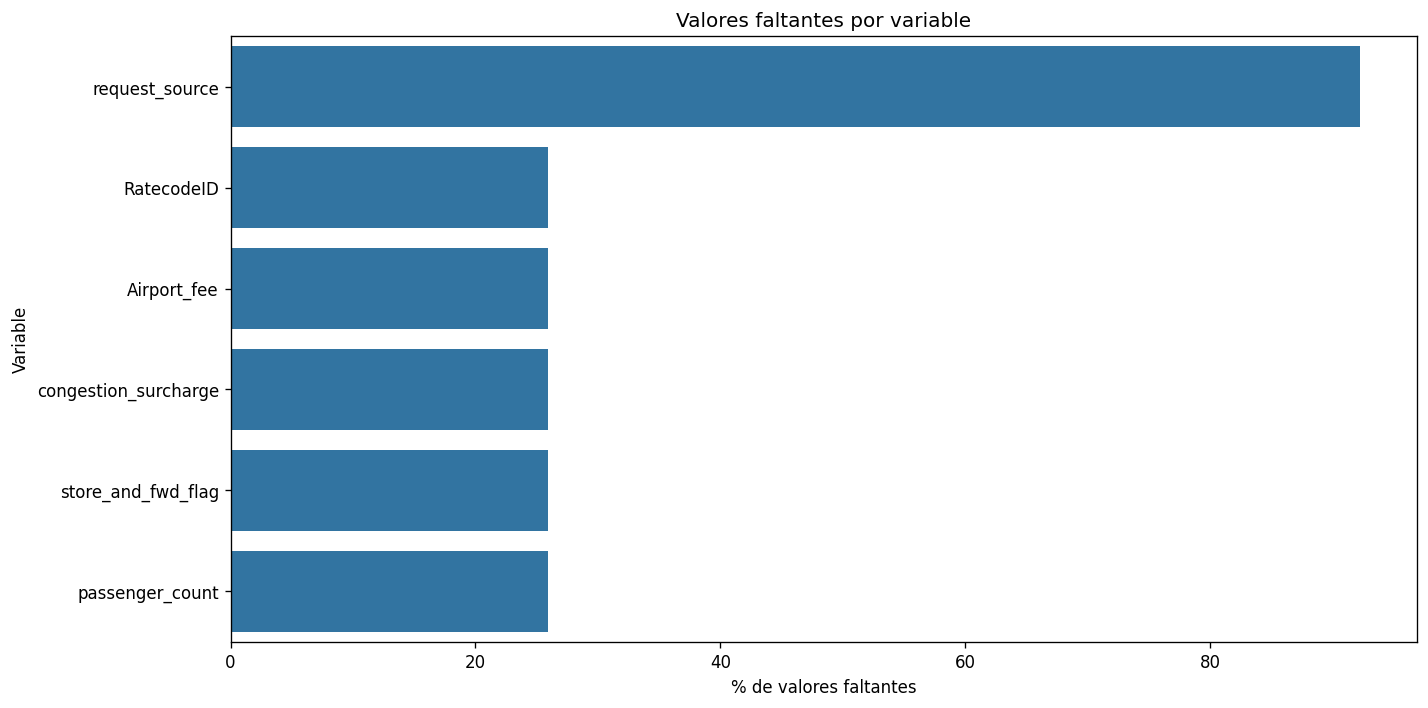

In [ ]:
# ============================================================
# 6.2 Visualización de missing values
# ============================================================

missing_plot = missing[missing["nulos"] > 0].head(20)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=missing_plot["porcentaje"],
    y=missing_plot.index
)
plt.xlabel("% de valores faltantes")
plt.ylabel("Variable")
plt.title("Valores faltantes por variable")
plt.tight_layout()
plt.show()

## 7. Duplicados

Se diferencia entre **duplicados exactos** y posibles duplicados lógicos. En esta etapa se cuantifican los duplicados exactos; la identificación de duplicados lógicos se reserva para reglas específicas de negocio.

In [ ]:
# ============================================================
# 7.1 Duplicados exactos
# ============================================================

duplicate_mask = df.duplicated(keep=False)

n_duplicates = duplicate_mask.sum()
pct_duplicates = duplicate_mask.mean() * 100

print(f"Duplicados exactos: {n_duplicates:,}")
print(f"Porcentaje: {pct_duplicates:.4f}%")

if n_duplicates > 0:
    display(df.loc[duplicate_mask].head(20))

Duplicados exactos: 0
Porcentaje: 0.0000%


## 8. Distribución de variables

Se analizan variables relevantes para el problema futuro: distancia, cantidad de pasajeros, tarifa y duración.

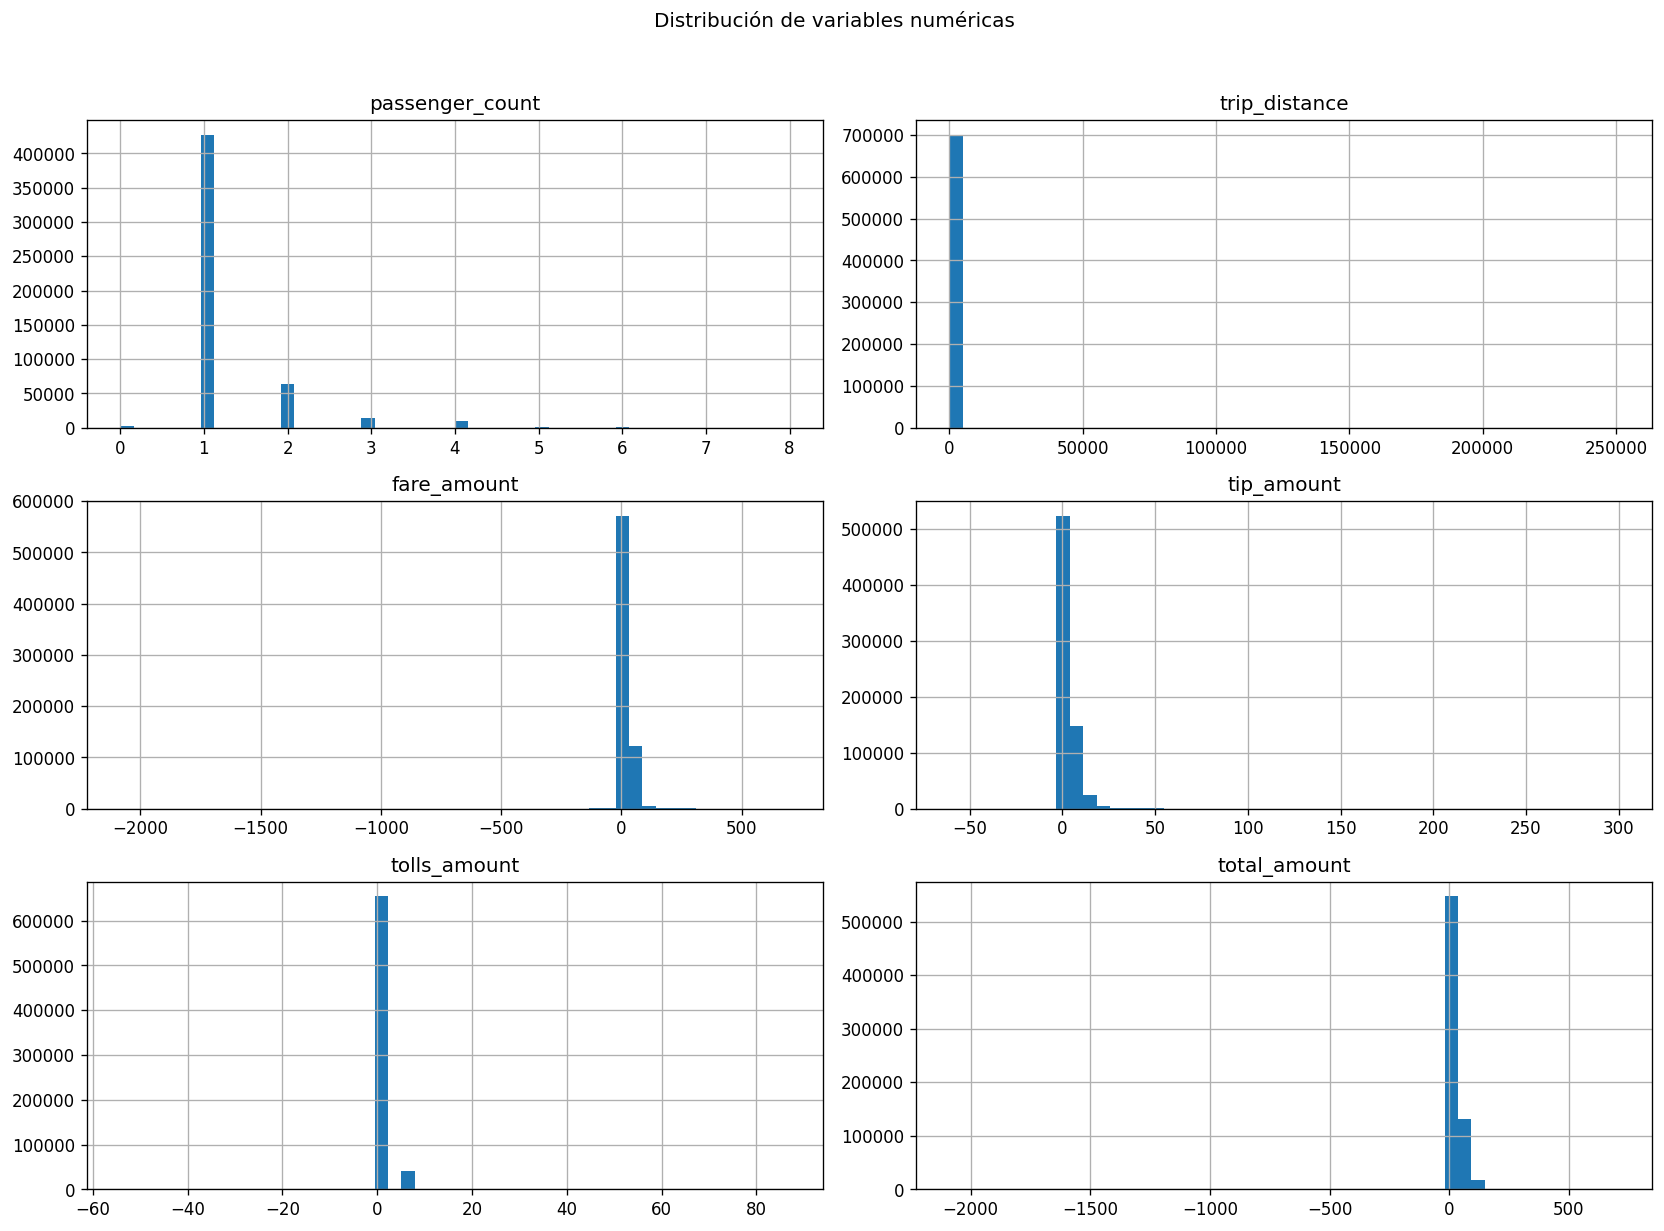

In [ ]:
# ============================================================
# 8.1 Variables numéricas
# ============================================================

numeric_candidates = [
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "tolls_amount",
    "total_amount"
]

numeric_candidates = [c for c in numeric_candidates if c in df.columns]

df[numeric_candidates].hist(
    figsize=(14, 10),
    bins=50
)
plt.suptitle("Distribución de variables numéricas", y=1.02)
plt.tight_layout()
plt.show()


## 9. Ingeniería de variables temporales

A partir de las fechas originales se crean variables que podrán utilizarse posteriormente en el modelo.

In [ ]:
# ============================================================
# 9.1 Variables derivadas
# ============================================================

df["tpep_pickup_datetime"] = pd.to_datetime(
    df["tpep_pickup_datetime"], errors="coerce"
)
df["tpep_dropoff_datetime"] = pd.to_datetime(
    df["tpep_dropoff_datetime"], errors="coerce"
)

df["trip_duration_minutes"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["pickup_hour"] = df["tpep_pickup_datetime"].dt.hour
df["pickup_day"] = df["tpep_pickup_datetime"].dt.day
df["pickup_month"] = df["tpep_pickup_datetime"].dt.month
df["pickup_weekday"] = df["tpep_pickup_datetime"].dt.dayofweek
df["is_weekend"] = df["pickup_weekday"].isin([5, 6]).astype(int)

display(
    df[
        [
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "trip_duration_minutes",
            "pickup_hour",
            "pickup_weekday",
            "is_weekend"
        ]
    ].head()
)

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration_minutes,pickup_hour,pickup_weekday,is_weekend
0,2026-01-18 12:35:13,2026-01-18 12:46:05,10.867,12,6,1
1,2026-01-28 01:01:57,2026-01-28 01:34:45,32.800,1,2,0
2,2026-01-09 10:35:27,2026-01-09 11:05:50,30.383,10,4,0
3,2026-01-24 22:26:51,2026-01-24 22:37:03,10.200,22,5,1
4,2026-01-01 01:59:23,2026-01-01 02:13:41,14.300,1,3,0


## 10. Validaciones de calidad y outliers

Se aplican reglas de negocio y métodos estadísticos. **Un outlier estadístico no se elimina automáticamente**: primero se identifica y luego se decide si representa un error o un caso extremo válido.

In [ ]:
# ============================================================
# 10.1 Reglas de calidad
# ============================================================

quality_checks = pd.Series({
    "pickup_nulo": df["tpep_pickup_datetime"].isna().sum(),
    "dropoff_nulo": df["tpep_dropoff_datetime"].isna().sum(),
    "dropoff_antes_pickup": (
        df["tpep_dropoff_datetime"] < df["tpep_pickup_datetime"]
    ).sum(),
    "duracion_no_positiva": (df["trip_duration_minutes"] <= 0).sum(),
    "pasajeros_no_positivos": (df["passenger_count"] <= 0).sum(),
    "distancia_no_positiva": (df["trip_distance"] <= 0).sum(),
    "fare_negativa": (df["fare_amount"] < 0).sum(),
    "total_negativo": (df["total_amount"] < 0).sum(),
})

display(quality_checks.to_frame("cantidad"))


,cantidad
pickup_nulo,0
dropoff_nulo,0
dropoff_antes_pickup,0
duracion_no_positiva,8823
pasajeros_no_positivos,2197
distancia_no_positiva,22229
fare_negativa,3860
total_negativo,3954


In [ ]:
# ============================================================
# 10.2 Detección de outliers mediante IQR
# ============================================================

def iqr_bounds(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_summary = []

for col in ["trip_distance", "trip_duration_minutes", "fare_amount"]:
    if col not in df.columns:
        continue

    s = df[col].dropna()
    lower, upper = iqr_bounds(s)
    mask = (df[col] < lower) | (df[col] > upper)

    outlier_summary.append({
        "variable": col,
        "limite_inferior": lower,
        "limite_superior": upper,
        "outliers": mask.sum(),
        "porcentaje": mask.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary)

,variable,limite_inferior,limite_superior,outliers,porcentaje
0,trip_distance,-3.115,7.885,77620,11.089
1,trip_duration_minutes,-12.333,42.733,37803,5.400
2,fare_amount,-14.735,51.225,47830,6.833


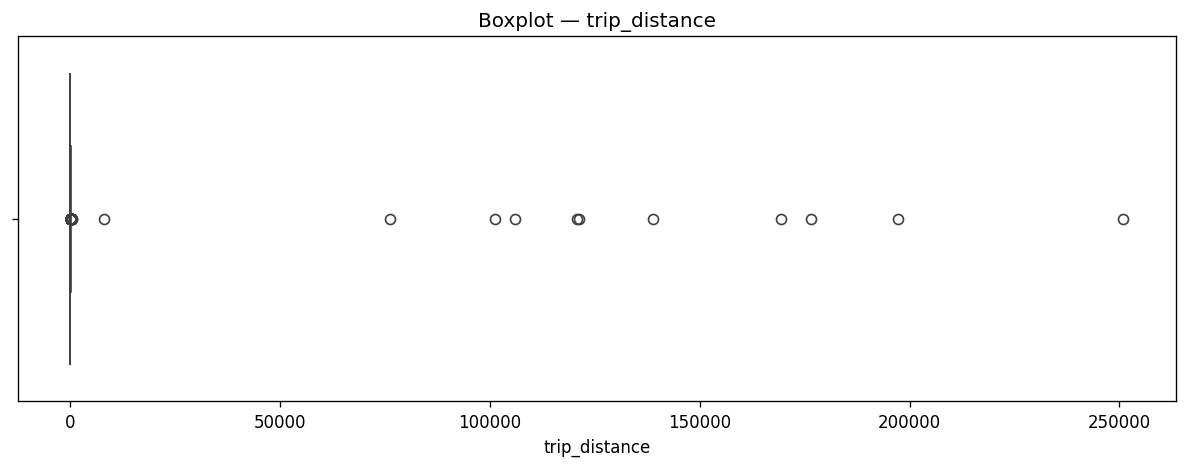

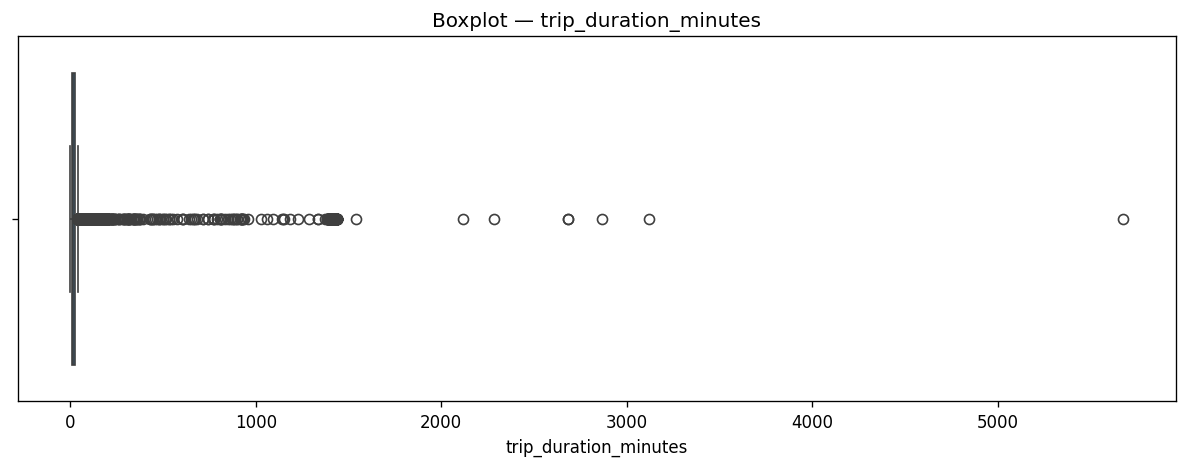

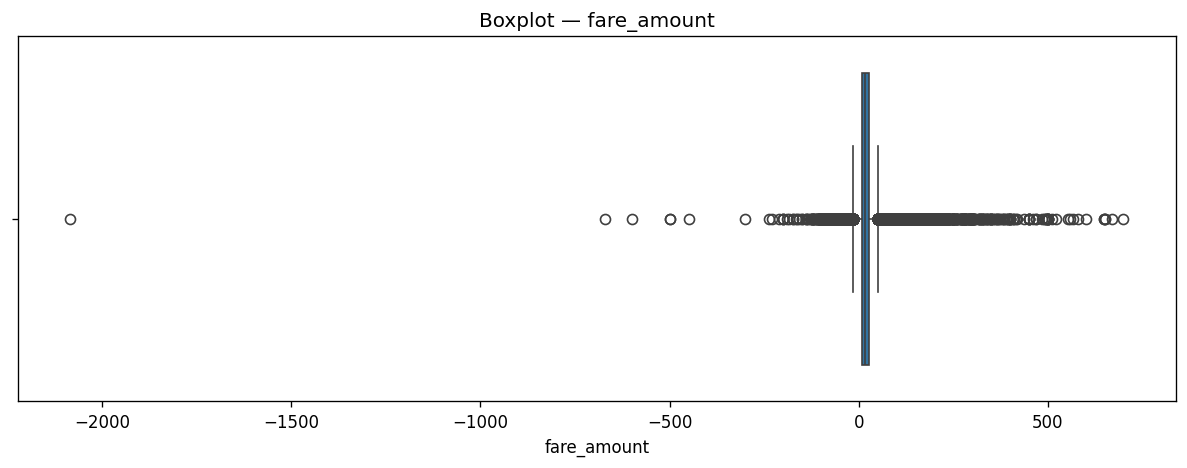

In [ ]:
# ============================================================
# 10.3 Boxplots
# ============================================================

for col in ["trip_distance", "trip_duration_minutes", "fare_amount"]:
    if col not in df.columns:
        continue

    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot — {col}")
    plt.tight_layout()
    plt.show()

## 11. Correlaciones

La matriz de correlación se utiliza como herramienta exploratoria. No se interpreta una correlación como causalidad.


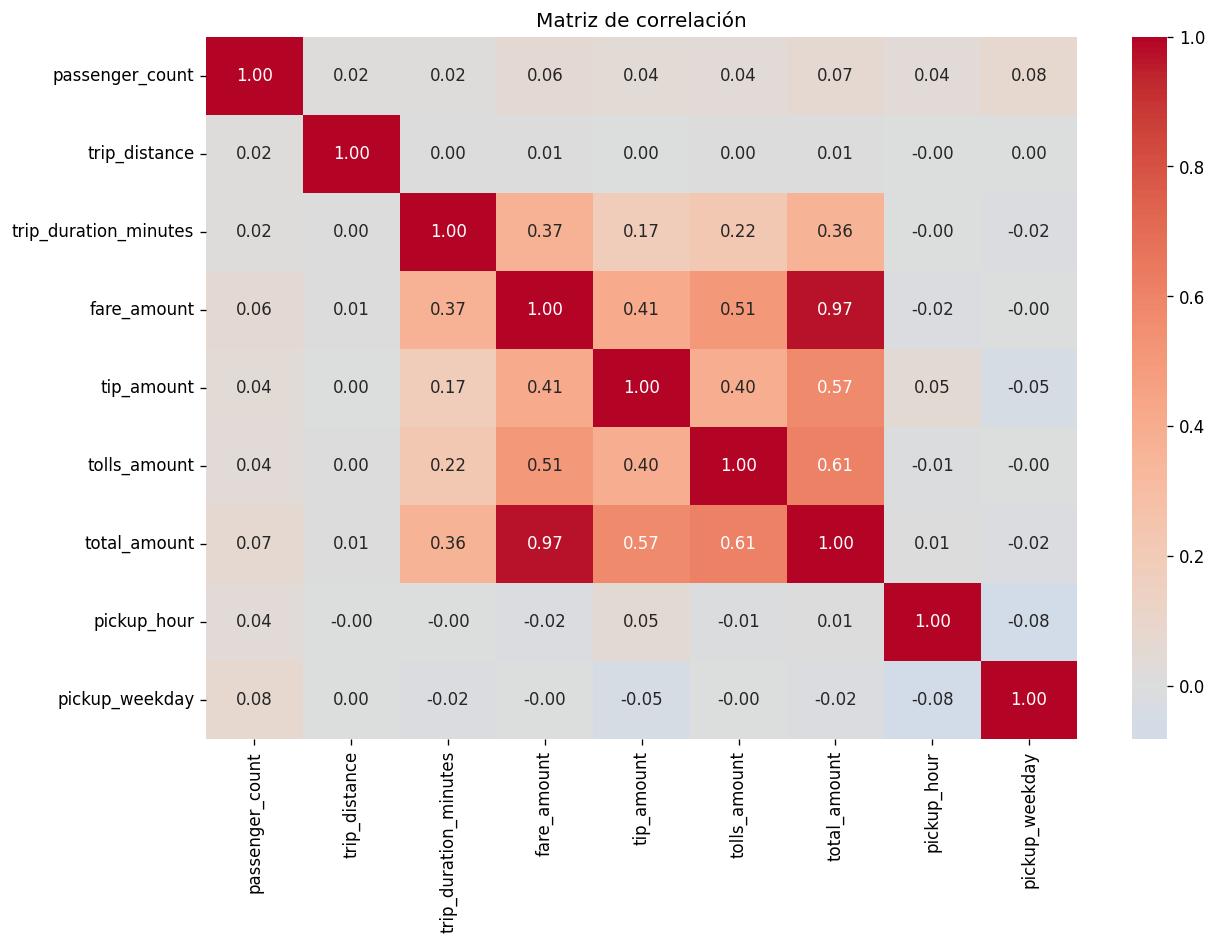

In [ ]:
# ============================================================
# 11.1 Matriz de correlación
# ============================================================

corr_cols = [
    "passenger_count",
    "trip_distance",
    "trip_duration_minutes",
    "fare_amount",
    "tip_amount",
    "tolls_amount",
    "total_amount",
    "pickup_hour",
    "pickup_weekday"
]

corr_cols = [c for c in corr_cols if c in df.columns]

corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

## 12. Limpieza de datos

La limpieza se realiza con reglas explícitas y documentadas.

### Criterios
- Eliminar duplicados exactos.
- Eliminar registros sin fechas esenciales.
- Eliminar viajes con duración no positiva.
- Eliminar valores claramente inválidos en variables fundamentales.
- Mantener inicialmente los outliers estadísticos que no puedan demostrarse como errores.
- Para variables categóricas/numericas que permanezcan con faltantes, definir una estrategia de imputación posterior al diagnóstico.

In [ ]:
# ============================================================
# 12.1 Limpieza
# ============================================================

df_clean = df.copy()

rows_before = len(df_clean)

# Duplicados exactos
df_clean = df_clean.drop_duplicates()

# Fechas esenciales
df_clean = df_clean.dropna(
    subset=["tpep_pickup_datetime", "tpep_dropoff_datetime"]
)

# Duración válida
df_clean = df_clean[df_clean["trip_duration_minutes"] > 0]

# Variables fundamentales
df_clean = df_clean[df_clean["passenger_count"] > 0]
df_clean = df_clean[df_clean["trip_distance"] > 0]
df_clean = df_clean[df_clean["fare_amount"] >= 0]

rows_after = len(df_clean)

print(f"Registros antes de limpieza: {rows_before:,}")
print(f"Registros después de limpieza: {rows_after:,}")
print(f"Registros eliminados: {rows_before - rows_after:,}")
print(f"Porcentaje eliminado: {(rows_before - rows_after)/rows_before*100:.2f}%")

Registros antes de limpieza: 700,000
Registros después de limpieza: 498,056
Registros eliminados: 201,944
Porcentaje eliminado: 28.85%


## 13. Tratamiento de valores faltantes

Se vuelve a medir la completitud después de la limpieza. La estrategia de imputación se aplica solamente a las variables que realmente se utilizarán para el futuro modelo.

In [ ]:
# ============================================================
# 13.1 Missing values después de la limpieza
# ============================================================

missing_clean = pd.DataFrame({
    "nulos": df_clean.isna().sum(),
    "porcentaje": df_clean.isna().mean() * 100
}).sort_values("porcentaje", ascending=False)

display(missing_clean[missing_clean["nulos"] > 0])

,nulos,porcentaje
request_source,498056,100.000


## 14. Variables y prevención de Data Leakage

### Variable objetivo
**fare_amount**

### Variables excluidas por posible Data Leakage
Se excluyen variables que representan componentes calculados a partir de la tarifa o información posterior al viaje:

- **tip_amount**
- **tolls_amount**
- **total_amount**
- **mta_tax**
- **extra**
- **improvement_surcharge**
- **congestion_surcharge**

La decisión evita que el futuro modelo utilice información que no estaría disponible de manera independiente para estimar la tarifa.

In [ ]:
# ============================================================
# 14.1 Selección inicial de variables
# ============================================================

target = "fare_amount"

candidate_features = [
    "passenger_count",
    "trip_distance",
    "trip_duration_minutes",
    "RatecodeID",
    "PULocationID",
    "DOLocationID",
    "payment_type",
    "pickup_hour",
    "pickup_month",
    "pickup_weekday",
    "is_weekend"
]

candidate_features = [c for c in candidate_features if c in df_clean.columns]

print("Variable objetivo:", target)
print("Variables candidatas:")
print(candidate_features)

Variable objetivo: fare_amount
Variables candidatas:
['passenger_count', 'trip_distance', 'trip_duration_minutes', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'pickup_hour', 'pickup_month', 'pickup_weekday', 'is_weekend']


## 15. Transformación de variables

Separamos variables numéricas y categóricas.

- Numéricas: imputación por mediana + escalado estándar.
- Categóricas: imputación por moda + One-Hot Encoding.

El preprocesamiento se ajustará posteriormente **solo con el conjunto de entrenamiento**, evitando leakage entre train y test.

In [ ]:
# ============================================================
# 15.1 Preparación de X e y
# ============================================================

model_df = df_clean[candidate_features + [target]].copy()

# Eliminamos filas sin target
model_df = model_df.dropna(subset=[target])

X = model_df[candidate_features]
y = model_df[target]

numeric_features = [
    c for c in candidate_features
    if pd.api.types.is_numeric_dtype(X[c])
]

categorical_features = [
    c for c in candidate_features
    if c not in numeric_features
]

print("Numéricas:", numeric_features)
print("Categóricas:", categorical_features)

Numéricas: ['passenger_count', 'trip_distance', 'trip_duration_minutes', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'pickup_hour', 'pickup_month', 'pickup_weekday', 'is_weekend']
Categóricas: []


In [ ]:
# ============================================================
# 15.2 Preprocesador
# ============================================================

numeric_transformer = Pipeline(
    steps=[
        ("imputer", __import__("sklearn").impute.SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", __import__("sklearn").impute.SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

## 16. División del dataset en entrenamiento y prueba

Como los datos son temporales, se utiliza una división cronológica para reducir el riesgo de utilizar información futura para representar el pasado.

**80% inicial → entrenamiento**  
**20% final → prueba**

In [ ]:
# ============================================================
# 16.1 División cronológica
# ============================================================

split_df = model_df.copy()

# Orden cronológico
split_df = split_df.join(
    df_clean.loc[split_df.index, "tpep_pickup_datetime"],
    how="left"
).sort_values("tpep_pickup_datetime")

split_idx = int(len(split_df) * 0.80)

train_df = split_df.iloc[:split_idx].copy()
test_df = split_df.iloc[split_idx:].copy()

X_train = train_df[candidate_features]
y_train = train_df[target]

X_test = test_df[candidate_features]
y_test = test_df[target]

print(f"Train: {len(train_df):,} registros")
print(f"Test:  {len(test_df):,} registros")
print(f"Proporción train: {len(train_df)/len(split_df):.2%}")
print(f"Proporción test:  {len(test_df)/len(split_df):.2%}")
print("\nPeríodo train:")
print(train_df["tpep_pickup_datetime"].min(), "→", train_df["tpep_pickup_datetime"].max())
print("\nPeríodo test:")
print(test_df["tpep_pickup_datetime"].min(), "→", test_df["tpep_pickup_datetime"].max())

Train: 398,444 registros
Test:  99,612 registros
Proporción train: 80.00%
Proporción test:  20.00%

Período train:
2026-01-01 00:00:38 → 2026-06-17 16:28:49

Período test:
2026-06-17 16:29:16 → 2026-07-31 23:57:44


In [ ]:
# ============================================================
# 16.2 Ajuste del preprocesador SOLO sobre train
# ============================================================

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print("Dimensión X_train transformado:", X_train_transformed.shape)
print("Dimensión X_test transformado:", X_test_transformed.shape)

Dimensión X_train transformado: (398444, 11)
Dimensión X_test transformado: (99612, 11)


## 17. Dataset final preparado

En esta etapa no se entrena ningún modelo. El objetivo es dejar documentado el dataset que se entregará a la segunda parte del curso.

### Resultado esperado
- datos explorados
- problemas de calidad identificados
- registros inválidos tratados
- variables derivadas creadas
- variables con posible leakage excluidas
- variables numéricas escaladas
- variables categóricas codificadas
- train/test definidos

In [ ]:
# ============================================================
# 17.1 Resumen final
# ============================================================

summary = pd.DataFrame({
    "Indicador": [
        "Registros RAW muestreados",
        "Registros después de limpieza",
        "Registros Train",
        "Registros Test",
        "Variables originales",
        "Variables candidatas al modelo",
        "Variables numéricas",
        "Variables categóricas"
    ],
    "Valor": [
        len(df),
        len(df_clean),
        len(train_df),
        len(test_df),
        df.shape[1],
        len(candidate_features),
        len(numeric_features),
        len(categorical_features)
    ]
})

display(summary)


,Indicador,Valor
0,Registros RAW muestreados,700000
1,Registros después de limpieza,498056
2,Registros Train,398444
3,Registros Test,99612
4,Variables originales,28
5,Variables candidatas al modelo,11
6,Variables numéricas,11
7,Variables categóricas,0


# 18. Conclusiones de la Pre-entrega

1. **Calidad inicial:**
El dataset analítico utilizado contiene 700.000 registros y 22 variables, correspondientes a una muestra de 100.000 registros por cada mes entre enero y julio de 2026.

El análisis inicial permitió identificar valores faltantes en seis variables:

| Variable                  | Valores faltantes | Proporción   |


| **request_source**        | 645.844           | **92,263 %** |
| **RatecodeID**            | 181.198           | **25,885 %** |
| **Airport_fee**           | 181.198           | **25,885 %** |
| **congestion_surcharge**  | 181.198           | **25,885 %** |
| **store_and_fwd_flag**    | 181.198           | **25,885 %** |
| **passenger_count**       | 181.198           | **25,885 %** |

Las restantes variables no presentan valores nulos en la muestra analizada.

El elevado porcentaje de valores faltantes en request_source constituye una característica relevante del dataset y deberá ser considerado durante la etapa de limpieza. En particular, no resulta conveniente eliminar registros exclusivamente por presentar este campo vacío debido a su elevada proporción de faltantes.

2. **Duplicados:**
Se realizó una búsqueda de duplicados exactos considerando la totalidad de las variables disponibles. El análisis identificó:

**0 registros duplicados exactos sobre 700.000 observaciones (0,00 %).**

Por lo tanto, no se eliminaron registros por duplicación.

Esta decisión se mantiene dado que no existe evidencia de duplicación exacta en la muestra analizada. No obstante, este resultado no descarta la existencia de posibles duplicados lógicos o registros correspondientes al mismo viaje con pequeñas diferencias en alguna variable.

3. **Outliers:**
El análisis mediante IQR identificó:

| Variable                  |Límite inferior|Límite superior|Outliers|%|
| **trip_distance**         |-3,115 | 7,885 |**77.620** |**11,089 %**|
| **trip_duration_minutes** |-12,333|42,733|**37.803**|**5,400 %**|
| **fare_amount**           |-14,733|51,225|**47.830**|**6,833 %**|

La detección inicial de valores extremos se realizó mediante el método del rango intercuartílico (IQR).

Se identificaron valores extremos en:
**trip_distance: 77.620 observaciones (11,089 %)**.
**trip_duration_minutes: 37.803 observaciones (5,400 %)**.
**fare_amount: 47.830 observaciones (6,833 %)**.

Estos valores no fueron eliminados automáticamente, debido a que un outlier estadístico no necesariamente constituye un error de datos.

Sin embargo, el análisis descriptivo permitió identificar valores potencialmente problemáticos que requieren tratamiento específico. Por ejemplo, trip_distance presenta un máximo de aproximadamente 250.937, mientras que fare_amount presenta valores negativos y un máximo de 700. También se observaron valores negativos en total_amount.

Por este motivo, además de la detección estadística mediante IQR, se utilizarán reglas de validación de negocio para distinguir entre valores extremos legítimos y registros potencialmente inválidos.

4. **Limpieza:**
En la etapa de validación se identificaron registros que incumplen determinadas reglas básicas de consistencia:

| Regla                          | Registros detectados |

| **Duración no positiva**       | 8.823                |
| **Pasajeros no positivos**     | 2.197                |    
| **Distancia no positiva**      | 22.229               |
| **fare_amount` negativo**      | 3.860                |
| **total_amount` negativo**     | 3.954                |

Estos conteos corresponden a condiciones individuales y pueden existir registros que incumplan simultáneamente más de una regla. Por este motivo, no se suman directamente para determinar la cantidad total de registros a eliminar.

La cantidad definitiva de registros eliminados se determinará aplicando las reglas de limpieza de manera conjunta y contabilizando las observaciones únicas afectadas. Los valores faltantes no serán tratados mediante eliminación indiscriminada de filas, sino considerando la naturaleza y relevancia de cada variable.

5. **Feature Engineering:**
A partir de las variables temporales originales se crearon nuevas características destinadas a representar dimensiones temporales y operativas del viaje.

**trip_duration_minutes**
Calcula la duración del viaje en minutos a partir de la diferencia entre **tpep_dropoff_datetime** y **tpep_pickup_datetime**. Esta variable permite incorporar al futuro modelo información sobre el tiempo requerido para completar el viaje.

**pickup_hour**
Representa la hora del día en que comienza el viaje. Permite capturar posibles diferencias en las tarifas asociadas a distintos períodos horarios.

**pickup_weekday**
Representa el día de la semana en que comienza el viaje, permitiendo incorporar patrones asociados a días laborables y fines de semana.

**is_weekend**
Variable binaria que identifica si el viaje ocurrió durante sábado o domingo. Se incorpora para simplificar la representación del efecto del fin de semana.

6. **Selección:**
Para la etapa del proyecto final se definió preliminarmente como variable objetivo **fare_amount**.

Como variables predictoras candidatas se conservarán aquellas que puedan aportar información disponible antes o durante la realización del viaje:

**trip_distance**
**trip_duration_minutes**
**passenger_count**
**PULocationID**
**DOLocationID**
**RatecodeID**
**payment_type**
**pickup_hour**
**pickup_weekday**
**is_weekend**

La selección definitiva será validada mediante el análisis exploratorio, correlaciones, cardinalidad de variables categóricas y evaluación del riesgo de data leakage.

7. **Data Leakage:**
Dado que el objetivo futuro será predecir fare_amount, se excluyeron o se consideran candidatas a exclusión las variables que contienen información derivada del importe final de la operación o información disponible únicamente una vez finalizado el viaje. Entre ellas se encuentran:

**total_amount**
**tip_amount**
**tolls_amount**
**extra**
**mta_tax**
**improvement_surcharge**
**congestion_surcharge**
**Airport_fee**
**cbd_congestion_fee**

Estas variables podrían proporcionar al modelo información directa o indirectamente derivada de la tarifa o de la liquidación final del viaje, generando una estimación artificialmente optimista. Las variables temporales originales se utilizaron para generar nuevas características como hora, día de semana y fin de semana, evitando conservar información temporal innecesaria para el modelo.

8. **Train/Test:**
Se optó por realizar una división cronológica en lugar de una división aleatoria.Dado que los registros poseen una dimensión temporal y el objetivo futuro consiste en predecir la tarifa de nuevos viajes, resulta más adecuado entrenar el modelo utilizando información de períodos anteriores y evaluar su comportamiento sobre un período posterior. En consecuencia, se propone utilizar:

**Entrenamiento: enero a junio de 2026.**
**Prueba: julio de 2026.**

Esta estrategia permite aproximar de mejor manera un escenario real de predicción, en el cual el modelo es entrenado utilizando información histórica y posteriormente aplicado a observaciones futuras. Además, evita introducir indirectamente información del período de prueba en el entrenamiento.

9. **Limitaciones:**
El presente trabajo corresponde a la etapa de preparación de datos del anteproyecto. En esta instancia no se realizó la selección ni el entrenamiento de un modelo predictivo, de acuerdo con el alcance definido para la pre-entrega. Por lo tanto, todavía no es posible determinar:

a. qué algoritmo tendrá mejor desempeño;
b. qué variables tendrán mayor importancia predictiva;
c. qué nivel de error tendrá el modelo;
d. ni si las transformaciones realizadas permitirán alcanzar un desempeño satisfactorio.

Estas cuestiones serán abordadas en la etapa de proyecto, una vez finalizado el proceso de preparación y división de los datos.

## 19. Revisión Post Pre-entrega y ajuste del pipeline de modelado (aca comienza la entrega final)

A partir de las conclusiones del punto **18** y de la devolución recibida de Ariel sobre la Pre-entrega (...Como mejora, revisaría con cuidado algunas variables candidatas, como payment_type y trip_duration_minutes, porque dependiendo del objetivo exacto podrían no estar disponibles al momento de estimar la tarifa. Si la predicción se piensa antes de que el viaje termine, esas variables deberían excluirse; si se piensa como estimación posterior o auditoría, podrían conservarse...), antes de iniciar el entrenamiento de modelos se precisan cuatro decisiones metodológicas sobre el dataset df ya construido:

### Definición del escenario operativo (Auditoría posterior al viaje)
- El modelo se plantea como una herramienta de **estimación posterior o auditoría tarifaria** sobre viajes finalizados (para detectar desvíos, errores de taxímetro o cobros atípicos).

¿Por que seleccionamos este enfoque? Por cinco razones técnicas, regulatorias y de continuidad:

1. Continuidad natural. En el anteproyecto ya había construido trip_duration_minutes en Ingeniería de Variables (sección 9.1) e incluido RatecodeID entre las candidatas. Ariel me planteó explícitamente las dos alternativas válidas: excluirlas si fuera una estimación previa al viaje, o conservarlas si se plantea como estimación posterior o auditoría. Elegir auditoría post-viaje valida y aprovecha el desarrollo que ya se venia modelando en las secciones 1 a 18.
2. Coherencia real con cómo se generan los datos de la TLC (evita Train-Serving Skew). En los archivos de NYC TLC, incluso **trip_distance** proviene del odómetro/taxímetro al terminar el recorrido, no de un estimador de ruta previo al viaje.
Si hubiéramos planteado un "cotizador antes de subir al taxi", en uso real tampoco tendríamos trip_distance medida por taxímetro (habría que pedirla a una API como Google Maps/OSRM, generando desfasaje entre entrenamiento y producción). En cambio, en Auditoría Post-Viaje auditamos lotes de viajes ya cerrados: todos los datos físicos del trayecto existen realmente en el momento de usar el modelo, lo que nos permite responder si funciona con los datos reales en la Pregunta Objetivo (**¿Podemos estimar el importe de la tarifa base (fare_amount) de un viaje a partir de sus características disponibles al momento del viaje?**).
3. Por qué conservar **trip_duration_minutes** y **RatecodeID**.
- **trip_duration_minutes** (física del taxímetro): El taxímetro de NYC tiene tarificación dual: cobra por distancia cuando el taxi supera 12 mph, pero cobra por minuto cuando va a menos de 12 mph o está detenido en tráfico. Dos viajes de igual distancia cuestan distinto según la congestión; sin la duración real sería imposible auditar con rigor si la tarifa cobrada fue legítima (fue la 2da variable más importante del modelo: +5,19 USD en MAE).
- **RatecodeID** (marco normativo del viaje): Distingue qué regla tarifaria rigió en ese viaje cerrado (1 = taxímetro estándar, 2 = tarifa plana JFK de USD 70, 3 = Newark, 4 = Nassau/Westchester, 5 = negociada). Fue la 3ra variable más importante (+3,11 USD) y es lo que permite auditar con error mediano de 0,33 USD los viajes estándar y 0,20 USD los de JFK.
4. Por qué excluir **payment_type** incluso después de terminar el viaje
- Independencia normativa: Por regulación de la TLC, la tarifa base (fare_amount) de un trayecto no debe cambiar según si el pasajero paga con tarjeta (1) o efectivo (2).
- Contaminación con eventos posteriores al cobro: **payment_type** incluye los códigos 3 = Sin cargo (No charge) y 4 = Disputa (Dispute), que se registran después de un reclamo o conflicto en la liquidación, justamente el tipo de anomalías que una auditoría debe evaluar de forma objetiva sin sesgarse por el resultado del cobro. Además, la única señal operativa útil de payment_type == 0 (Flex Fare) ya queda capturada limpiamente por el Pipeline mediante la categoría "Missing_FlexFare" en RatecodeID y el indicador de faltante en passenger_count.
5. Por qué excluir las variables monetarias derivadas (**total_amount, tip_amount, tolls_amount, impuestos y recargos**)
- Prevención de Data Leakage contable e inutilidad para auditar: **total_amount** se calcula sumando fare_amount más recargos, peajes y propinas (y en pagos con tarjeta tip_amount suele ser un porcentaje directo de la tarifa). Si un modelo de auditoría usara **total_amount**, simplemente despejaría la suma contable: si un taxímetro cobró por error o fraude USD 200 en vez de USD 20, total_amount también sería ~USD 205 y el modelo validaría erróneamente esos USD 200 como normales en lugar de detectar el desvío.

- Bajo este objetivo, al finalizar el viaje ya se conocen la duración real (**trip_duration_minutes**) y el régimen tarifario aplicado (**RatecodeID**), por lo que ambas variables **se conservan**.
- En cambio, se **excluye `payment_type`**, dado que la tarifa base reglamentaria no debe depender del medio de pago ni contaminarse con estados posteriores al cobro (3 = Sin cargo, 4 = Disputa), y se excluye **pickup_month** para evitar introducir en la evaluación de julio un valor de mes no observado durante el entrenamiento.

### Regla de separación Pre-Pipeline vs. Pipeline
- **Antes del pipeline (limpieza estructural y decisiones manuales):**
  - Conservar los registros con **passenger_count** y **RatecodeID** faltantes (NaN), que corresponden a viajes de aplicación (*Flex Fare*, payment_type == 0), filtrando únicamente valores declarados no positivos (<= 0).
  - Acotar errores físicos extremos de sensor detectados en el EDA (como distancias de 250.937 millas o velocidades medias físicamente imposibles) sin eliminar outliers válidos por IQR.
  - Tipar explícitamente **RatecodeID, PULocationID y DOLocationID** como variables categóricas nominales.
  - Separar **X** e **y** y aplicar la división cronológica planteada en el punto **18.8**: **enero a junio de 2026 para entrenamiento** y **julio de 2026 para prueba final**.
- **Dentro del pipeline (transformaciones que aprenden de los datos):**
  - Imputación de faltantes, indicadores de ausencia, escalado estándar y codificación *One-Hot* unidos directamente al estimador, ajustados exclusivamente sobre el conjunto de entrenamiento.

In [ ]:
# ============================================================
# 19.1 Consolidación de limpieza estructural y división cronológica
# ============================================================

import time
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit, cross_validate, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    mean_absolute_error,
    median_absolute_error,
    root_mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

# Liberar matrices intermedias de demostración creadas en el punto 16.2
for _tmp_var in ["X_train_transformed", "X_test_transformed", "split_df", "model_df"]:
    if _tmp_var in globals():
        del globals()[_tmp_var]

# Retomamos df (700.000 observaciones con variables temporales ya creadas en el punto 9.1)
df_final = df.drop_duplicates().copy()
df_final = df_final.dropna(subset=["tpep_pickup_datetime", "tpep_dropoff_datetime", "fare_amount"])

# Velocidad media implícita (mph) solo para validar consistencia física distancia/tiempo
df_final["avg_speed_mph"] = np.where(
    df_final["trip_duration_minutes"] > 0,
    df_final["trip_distance"] / (df_final["trip_duration_minutes"] / 60.0),
    np.nan
)

# Reglas físicas y de negocio (conservando NaN en passenger_count y RatecodeID para no perder viajes Flex Fare)
df_final = df_final[
    (df_final["tpep_pickup_datetime"] >= "2026-01-01") &
    (df_final["tpep_pickup_datetime"] < "2026-08-01") &
    (df_final["trip_duration_minutes"] >= 0.5) &
    (df_final["trip_duration_minutes"] <= 300.0) &
    (df_final["trip_distance"] >= 0.1) &
    (df_final["trip_distance"] <= 150.0) &
    (df_final["avg_speed_mph"] >= 0.5) &
    (df_final["avg_speed_mph"] <= 85.0) &
    (df_final["fare_amount"] >= 3.0) &
    (df_final["fare_amount"] <= 500.0) &
    ((df_final["passenger_count"] > 0) | (df_final["passenger_count"].isna()))
].copy()

# Tipado explícito de códigos nominales como texto (preservando np.nan para que impute el Pipeline)
for col_cat in ["RatecodeID", "PULocationID", "DOLocationID"]:
    df_final[col_cat] = df_final[col_cat].apply(lambda v: str(int(v)) if pd.notna(v) else np.nan)

# Selección definitiva de variables (escenario de auditoría post-viaje)
target = "fare_amount"

numeric_features = [
    "trip_distance",
    "trip_duration_minutes",
    "passenger_count",
    "pickup_hour",
    "pickup_weekday",
    "is_weekend"
]
categorical_low = ["RatecodeID"]
categorical_high = ["PULocationID", "DOLocationID"]
final_features = numeric_features + categorical_low + categorical_high

# Orden cronológico estricto y partición Enero-Junio (Train) vs Julio (Test)
df_final = df_final.sort_values("tpep_pickup_datetime").reset_index(drop=True)

train_df = df_final[df_final["tpep_pickup_datetime"] < "2026-07-01"].copy()
test_df = df_final[df_final["tpep_pickup_datetime"] >= "2026-07-01"].copy()

X_train = train_df[final_features].copy()
y_train = train_df[target].copy()

X_test = test_df[final_features].copy()
y_test = test_df[target].copy()

print(f"Registros válidos consolidados: {len(df_final):,} ({len(df_final)/len(df)*100:.2f}% del dataset analítico)")
print(f"Viajes Flex Fare preservados (NaN en RatecodeID): {df_final['RatecodeID'].isna().sum():,} ({df_final['RatecodeID'].isna().mean()*100:.2f}%)")
print(f"\nConjunto Train (Ene-Jun 2026): {len(X_train):,} registros | {train_df['tpep_pickup_datetime'].min()} -> {train_df['tpep_pickup_datetime'].max()}")
print(f"Conjunto Test  (Jul 2026):     {len(X_test):,} registros | {test_df['tpep_pickup_datetime'].min()} -> {test_df['tpep_pickup_datetime'].max()}")

Registros válidos consolidados: 657,130 (93.88% del dataset analítico)
Viajes Flex Fare preservados (NaN en RatecodeID): 161,533 (24.58%)

Conjunto Train (Ene-Jun 2026): 563,575 registros | 2026-01-01 00:00:38 -> 2026-06-30 23:59:56
Conjunto Test  (Jul 2026):     93,555 registros | 2026-07-01 00:00:04 -> 2026-07-31 23:59:58


El refinamiento estructural conserva **657.130 viajes válidos (93,88 %)** sobre los 700.000 originales, preservando los **161.533 viajes *Flex Fare* (24,58 %)** que antes quedaban excluidos al filtrar nulos en **passenger_count**. La partición respeta exactamente el esquema temporal planteado en las conclusiones de la Pre-entrega: **563.575 viajes de enero a junio de 2026** para entrenamiento/validación y **93.555 viajes de julio de 2026** reservados intactos para la evaluación final.

In [ ]:
# ============================================================
# 19.2 Definición del preprocesador integrable al Pipeline
# ============================================================

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler())
    ]
)

ratecode_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing_FlexFare")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]
)

location_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=40, sparse_output=False))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("rate", ratecode_transformer, categorical_low),
        ("loc", location_transformer, categorical_high)
    ],
    remainder="drop"
)

print("Variables numéricas (6):", numeric_features)
print("Variables categóricas (3):", categorical_low + categorical_high)
print("\nPreprocesador listo para integrarse dentro de Pipeline junto a cada modelo.")

Variables numéricas (6): ['trip_distance', 'trip_duration_minutes', 'passenger_count', 'pickup_hour', 'pickup_weekday', 'is_weekend']
Variables categóricas (3): ['RatecodeID', 'PULocationID', 'DOLocationID']

Preprocesador listo para integrarse dentro de Pipeline junto a cada modelo.


El **ColumnTransformer** no se ajusta de forma aislada fuera del flujo de modelado: al unirse con cada algoritmo mediante **Pipeline**, los parámetros de imputación (**median** con indicador de faltante en numéricas y categoría **"Missing_FlexFare"** en **RatecodeID**), escalado (**StandardScaler**) y codificación de las 40 zonas más frecuentes (**OneHotEncoder**) se aprenden **únicamente con los datos de entrenamiento de cada pliegue**.

## 20. Elección de los modelos y métricas de evaluación

### Justificación según el tipo de problema (Regresión)
Dado que la variable objetivo **fare_amount** es numérica continua (expresada en dólares estadounidenses), el problema corresponde a una tarea de **regresión supervisada**. Para evaluar el aporte real de mayor complejidad algorítmica, se comparan cuatro modelos dentro de un mismo esquema de Pipeline:

- **DummyRegressor (Referencia base):** predice siempre la tarifa media del conjunto de entrenamiento. Establece el piso mínimo de referencia.
- **Ridge (Regresión lineal con regularización $L_2$):** modela una relación lineal aditiva entre distancia, duración, régimen tarifario y zonas, controlando mediante penalización $L_2$ la colinealidad generada por el **One-Hot Encoding**. Representa el comportamiento base de un taxímetro lineal.
- **RandomForestRegressor (Ensamble Bagging de árboles):** combina árboles de decisión independientes entrenados sobre submuestras aleatorias, permitiendo capturar umbrales no lineales e interacciones entre origen, destino y congestión.
- **HistGradientBoostingRegressor (Gradient Boosting por histogramas):** ensamble secuencial de árboles que corrige iterativamente los residuos de los árboles previos, optimizado para datasets voluminosos con relaciones no lineales y regímenes tarifarios mixtos.

### Métricas de evaluación seleccionadas
En lugar de evaluar únicamente con $R^2$, se utilizan cinco métricas complementarias adecuadas para regresión tarifaria:

- **MAE (*Mean Absolute Error*, USD):** error absoluto promedio en dólares; mide directamente cuánto se desvía en promedio la tarifa estimada.
- **MedAE (*Median Absolute Error*, USD):** mediana del error absoluto; resume el error en un viaje típico sin distorsión por casos extremos.
- **RMSE (*Root Mean Squared Error*, USD):** raíz del error cuadrático medio; penaliza con mayor peso los desvíos grandes.
- **MAPE (*Mean Absolute Percentage Error*, %):** error relativo expresado como porcentaje de la tarifa real.
- **$R^2$ (*Coeficiente de determinación*):** proporción de la varianza de **fare_amount** explicada por el modelo.

## 21. Entrenamiento preliminar y validación cruzada

Para estimar el rendimiento de manera robusta respetando el orden cronológico de los viajes, se aplica **TimeSeriesSplit de 5 capas** sobre el conjunto de entrenamiento (enero a junio de 2026). En cada corte se entrena con períodos anteriores y se valida sobre el bloque temporal siguiente, comparando además el desempeño en entrenamiento y validación para detectar posible *overfitting*.

In [ ]:
# ============================================================
# 21.1 Validación cruzada temporal (TimeSeriesSplit) sobre Train
# ============================================================

tscv = TimeSeriesSplit(n_splits=5)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

models = {
    "Dummy (Media)": DummyRegressor(strategy="mean"),
    "Ridge (Lineal L2)": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=60,
        max_depth=16,
        min_samples_leaf=20,
        max_samples=0.25,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=31,
        min_samples_leaf=30,
        random_state=RANDOM_STATE
    )
}

cv_summary = []
cv_folds = []

for name, model in models.items():
    t0 = time.time()
    pipe = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=tscv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1
    )
    elapsed = time.time() - t0

    cv_summary.append({
        "modelo": name,
        "train_MAE": -scores["train_MAE"].mean(),
        "valid_MAE": -scores["test_MAE"].mean(),
        "valid_MAE_std": scores["test_MAE"].std(),
        "train_RMSE": -scores["train_RMSE"].mean(),
        "valid_RMSE": -scores["test_RMSE"].mean(),
        "train_R2": scores["train_R2"].mean(),
        "valid_R2": scores["test_R2"].mean(),
        "tiempo_seg": elapsed
    })

    for fold_i in range(tscv.n_splits):
        cv_folds.append({
            "modelo": name,
            "fold": f"Fold {fold_i + 1}",
            "valid_MAE": -scores["test_MAE"][fold_i],
            "valid_R2": scores["test_R2"][fold_i]
        })

cv_summary_df = pd.DataFrame(cv_summary)
cv_folds_df = pd.DataFrame(cv_folds)

display(cv_summary_df)

,modelo,train_MAE,valid_MAE,valid_MAE_std,train_RMSE,valid_RMSE,train_R2,valid_R2,tiempo_seg
0,Dummy (Media),12.015,12.054,0.168,17.218,17.389,0.000,-0.001,8.843
1,Ridge (Lineal L2),3.311,3.166,0.150,6.605,6.398,0.853,0.864,10.028
2,Random Forest,2.168,2.097,0.217,5.644,5.622,0.892,0.895,73.196
3,HistGradientBoosting,2.139,2.070,0.194,5.247,5.381,0.907,0.904,50.607


La validación cruzada temporal evidencia una mejora clara al pasar de modelos simples a ensambles no lineales: el error medio (valid_MAE) desciende desde **12,054 USD** en DummyRegressor a **3,166 USD** en Ridge (valid_R2 = 0,864), **2,097 USD** en Random Forest (valid_R2 = 0,895) y **2,070 USD** en HistGradientBoosting (valid_RMSE = 5,381 USD, valid_R2 = 0,904), que además entrena más rápido que Random Forest. La proximidad entre las métricas de train y valid en los cuatro casos confirma que **no existe overfitting relevante**.

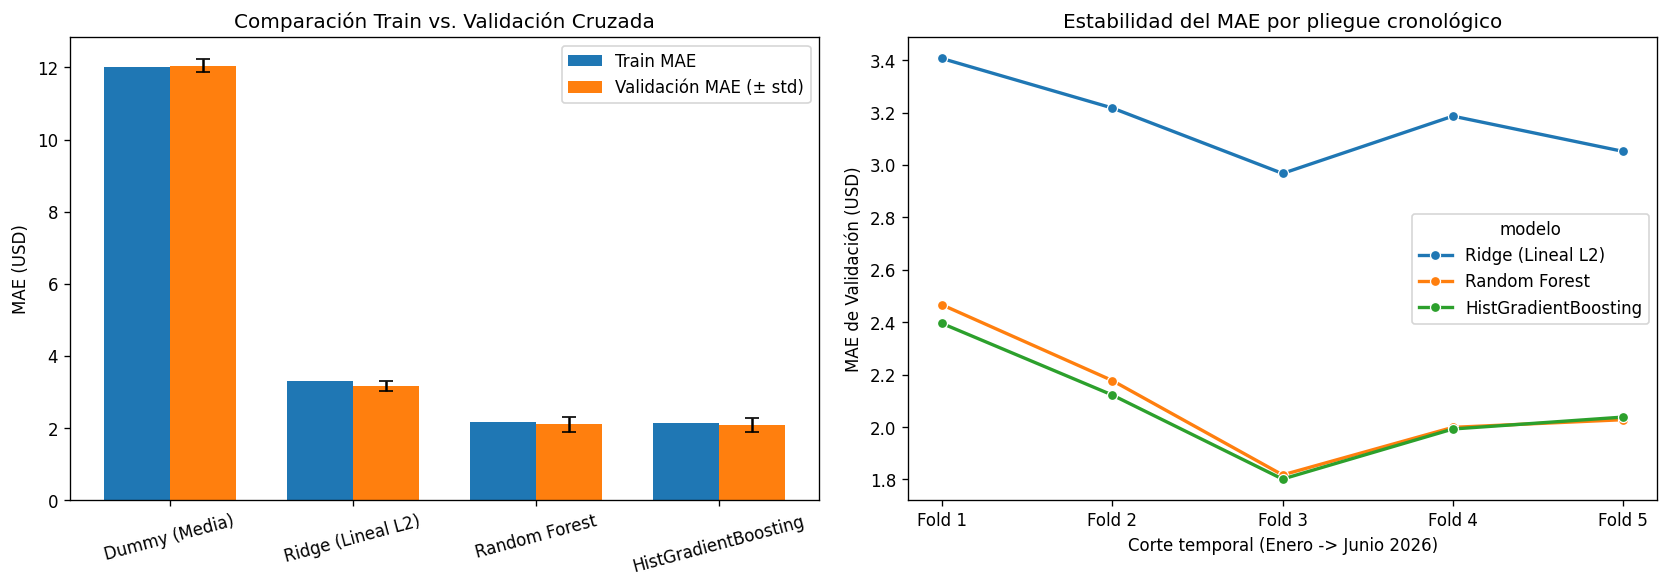

In [ ]:
# ============================================================
# 21.2 Comparación visual entre entrenamiento y validación cruzada
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_idx = np.arange(len(cv_summary_df))
bar_w = 0.36

axes[0].bar(x_idx - bar_w / 2, cv_summary_df["train_MAE"], width=bar_w, label="Train MAE")
axes[0].bar(
    x_idx + bar_w / 2,
    cv_summary_df["valid_MAE"],
    width=bar_w,
    yerr=cv_summary_df["valid_MAE_std"],
    capsize=4,
    label="Validación MAE (± std)"
)
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(cv_summary_df["modelo"], rotation=15)
axes[0].set_ylabel("MAE (USD)")
axes[0].set_title("Comparación Train vs. Validación Cruzada")
axes[0].legend()

folds_no_dummy = cv_folds_df[cv_folds_df["modelo"] != "Dummy (Media)"]
sns.lineplot(
    data=folds_no_dummy,
    x="fold",
    y="valid_MAE",
    hue="modelo",
    marker="o",
    linewidth=2,
    ax=axes[1]
)
axes[1].set_xlabel("Corte temporal (Enero -> Junio 2026)")
axes[1].set_ylabel("MAE de Validación (USD)")
axes[1].set_title("Estabilidad del MAE por pliegue cronológico")

plt.tight_layout()
plt.show()

Los gráficos muestran que HistGradientBoosting obtiene sistemáticamente el menor **MAE** en los cinco cortes cronológicos y mantiene alineadas las barras de entrenamiento y validación. Por precisión, estabilidad temporal y eficiencia computacional, se lo selecciona para la etapa de ajuste fino de hiperparámetros.

## 22. Optimización de hiperparámetros y entrenamiento del modelo final

Se aplica **GridSearchCV** sobre el Pipeline completo de HistGradientBoostingRegressor empleando validación cruzada temporal (TimeSeriesSplit) para ajustar la tasa de aprendizaje (learning_rate), la cantidad máxima de hojas por árbol (max_leaf_nodes) y la regularización $L_2$ (l2_regularization). Con refit=True, el mejor pipeline queda entrenado sobre todo el conjunto X_train (enero a junio de 2026).

In [ ]:
# ============================================================
# 22.1 Ajuste con GridSearchCV y entrenamiento final sobre Train
# ============================================================

hgb_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", HistGradientBoostingRegressor(
            max_iter=180,
            min_samples_leaf=30,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=15,
            random_state=RANDOM_STATE
        ))
    ]
)

param_grid = {
    "model__learning_rate": [0.05, 0.10],
    "model__max_leaf_nodes": [31, 63],
    "model__l2_regularization": [0.0, 1.0]
}

grid_search = GridSearchCV(
    estimator=hgb_pipe,
    param_grid=param_grid,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_mean_absolute_error",
    return_train_score=True,
    refit=True,
    n_jobs=1
)

grid_search.fit(X_train, y_train)

grid_results = pd.DataFrame(grid_search.cv_results_)[[
    "rank_test_score",
    "param_model__learning_rate",
    "param_model__max_leaf_nodes",
    "param_model__l2_regularization",
    "mean_train_score",
    "mean_test_score",
    "std_test_score"
]].copy()

grid_results["train_MAE"] = -grid_results["mean_train_score"]
grid_results["valid_MAE"] = -grid_results["mean_test_score"]
grid_results["valid_MAE_std"] = grid_results["std_test_score"]
grid_results = grid_results.drop(
    columns=["mean_train_score", "mean_test_score", "std_test_score"]
).sort_values("rank_test_score")

print("Mejores hiperparámetros:", grid_search.best_params_)
print(f"Mejor MAE promedio en CV: {-grid_search.best_score_:.3f} USD")
display(grid_results)

# Modelos de referencia ajustados también sobre X_train para comparación en Test
baseline_dummy = Pipeline([("preprocessor", preprocessor), ("model", DummyRegressor(strategy="mean"))]).fit(X_train, y_train)
baseline_ridge = Pipeline([("preprocessor", preprocessor), ("model", Ridge(alpha=1.0))]).fit(X_train, y_train)
final_model = grid_search.best_estimator_

Mejores hiperparámetros: {'model__l2_regularization': 0.0, 'model__learning_rate': 0.1, 'model__max_leaf_nodes': 63}
Mejor MAE promedio en CV: 1.990 USD


,rank_test_score,param_model__learning_rate,param_model__max_leaf_nodes,param_model__l2_regularization,train_MAE,valid_MAE,valid_MAE_std
3,1,0.100,63,0.000,2.057,1.990,0.142
1,2,0.050,63,0.000,2.098,1.991,0.142
7,3,0.100,63,1.000,2.064,1.991,0.143
5,4,0.050,63,1.000,2.099,1.991,0.143
2,5,0.100,31,0.000,2.132,2.022,0.139
6,6,0.100,31,1.000,2.135,2.025,0.139
0,7,0.050,31,0.000,2.175,2.033,0.139
4,8,0.050,31,1.000,2.176,2.035,0.138


El factor más influyente de la grilla es incrementar max_leaf_nodes de 31 a 63, reduciendo el **MAE** de validación cruzada hasta **1,990 USD** en los cuatro primeros lugares del ranking gracias a una mejor representación de las interacciones entre RatecodeID, zonas aeroportuarias y relación distancia–tiempo, manteniendo controlada la diferencia frente a entrenamiento (train_MAE = 2,057 USD).

## 23. Evaluación final sobre el conjunto de prueba (Test)

Finalizada la selección y el ajuste de hiperparámetros usando únicamente datos de enero a junio, se evalúa el pipeline ganador **una sola vez** sobre el conjunto de prueba reservado (**julio de 2026**, 93.555 viajes futuros). Se reportan todas las métricas definidas junto con sus intervalos de confianza al 95 % calculados mediante *bootstrapping*.

In [ ]:
# ============================================================
# 23.1 Evaluación única sobre Test (Julio 2026)
# ============================================================

def compute_metrics(y_true, y_pred, label):
    return {
        "modelo_conjunto": label,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MedAE": median_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MAPE_%": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "R2": r2_score(y_true, y_pred)
    }

pred_dummy_test = baseline_dummy.predict(X_test)
pred_ridge_test = baseline_ridge.predict(X_test)
pred_train_final = final_model.predict(X_train)
pred_test_final = final_model.predict(X_test)

test_metrics_df = pd.DataFrame([
    compute_metrics(y_test, pred_dummy_test, "Dummy (Media) — Test Julio"),
    compute_metrics(y_test, pred_ridge_test, "Ridge (Lineal L2) — Test Julio"),
    compute_metrics(y_train, pred_train_final, "HistGradientBoosting Final — Train (Ene-Jun)"),
    compute_metrics(y_test, pred_test_final, "HistGradientBoosting Final — Test (Julio)")
])
display(test_metrics_df)

# Intervalos de confianza Bootstrap al 95 % sobre Test
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
abs_err = np.abs(y_arr - pred_test_final)
sq_err = (y_arr - pred_test_final) ** 2
pct_err = abs_err / y_arr * 100.0

n_obs = len(y_arr)
b_mae, b_medae, b_rmse, b_r2 = [], [], [], []
for _ in range(500):
    idx = rng.integers(0, n_obs, size=n_obs)
    b_mae.append(abs_err[idx].mean())
    b_medae.append(np.median(abs_err[idx]))
    b_rmse.append(np.sqrt(sq_err[idx].mean()))
    yb = y_arr[idx]
    b_r2.append(1.0 - sq_err[idx].sum() / np.sum((yb - yb.mean()) ** 2))

ci_test_df = pd.DataFrame([
    {"metrica": "MAE (USD)", "valor_test": mean_absolute_error(y_test, pred_test_final), "IC_95_inf": np.percentile(b_mae, 2.5), "IC_95_sup": np.percentile(b_mae, 97.5)},
    {"metrica": "MedAE (USD)", "valor_test": median_absolute_error(y_test, pred_test_final), "IC_95_inf": np.percentile(b_medae, 2.5), "IC_95_sup": np.percentile(b_medae, 97.5)},
    {"metrica": "RMSE (USD)", "valor_test": root_mean_squared_error(y_test, pred_test_final), "IC_95_inf": np.percentile(b_rmse, 2.5), "IC_95_sup": np.percentile(b_rmse, 97.5)},
    {"metrica": "R2", "valor_test": r2_score(y_test, pred_test_final), "IC_95_inf": np.percentile(b_r2, 2.5), "IC_95_sup": np.percentile(b_r2, 97.5)}
])
print("\nIntervalos de confianza al 95 % en Test (Julio 2026):")
display(ci_test_df)

,modelo_conjunto,MAE,MedAE,RMSE,MAPE_%,R2
0,Dummy (Media) — Test Julio,11.772,9.877,17.369,81.204,-0.001
1,Ridge (Lineal L2) — Test Julio,3.181,1.556,6.085,19.360,0.877
2,HistGradientBoosting Final — Train (Ene-Jun),1.934,0.482,4.931,9.947,0.919
3,HistGradientBoosting Final — Test (Julio),2.220,0.519,5.542,12.619,0.898



Intervalos de confianza al 95 % en Test (Julio 2026):


,metrica,valor_test,IC_95_inf,IC_95_sup
0,MAE (USD),2.220,2.187,2.254
1,MedAE (USD),0.519,0.513,0.524
2,RMSE (USD),5.542,5.242,5.872
3,R2,0.898,0.888,0.907


Sobre los **93.555 viajes de julio de 2026**, el modelo final alcanza **MAE = 2,220 USD**, **MedAE = 0,519 USD**, **RMSE = 5,542 USD**, **MAPE = 12,62 %** y **R² = 0,898** (reduciendo el **MAE** un **81,1 %** respecto de Dummy y un **30,2 %** respecto de Ridge). En el 50 % de los viajes futuros el error absoluto no supera los **52 centavos de dólar** (MedAE = 0,519 USD), mientras que la diferencia entre MedAE y RMSE sugiere que los errores grandes están concentrados en subgrupos puntuales que se analizan en la siguiente sección.

## 24. Visualización de resultados e interpretación de errores o aciertos

Se inspecciona gráficamente el ajuste del modelo final sobre Test, la importancia predictiva de cada variable mediante permutación y el desglose de aciertos y errores según el régimen tarifario del viaje.

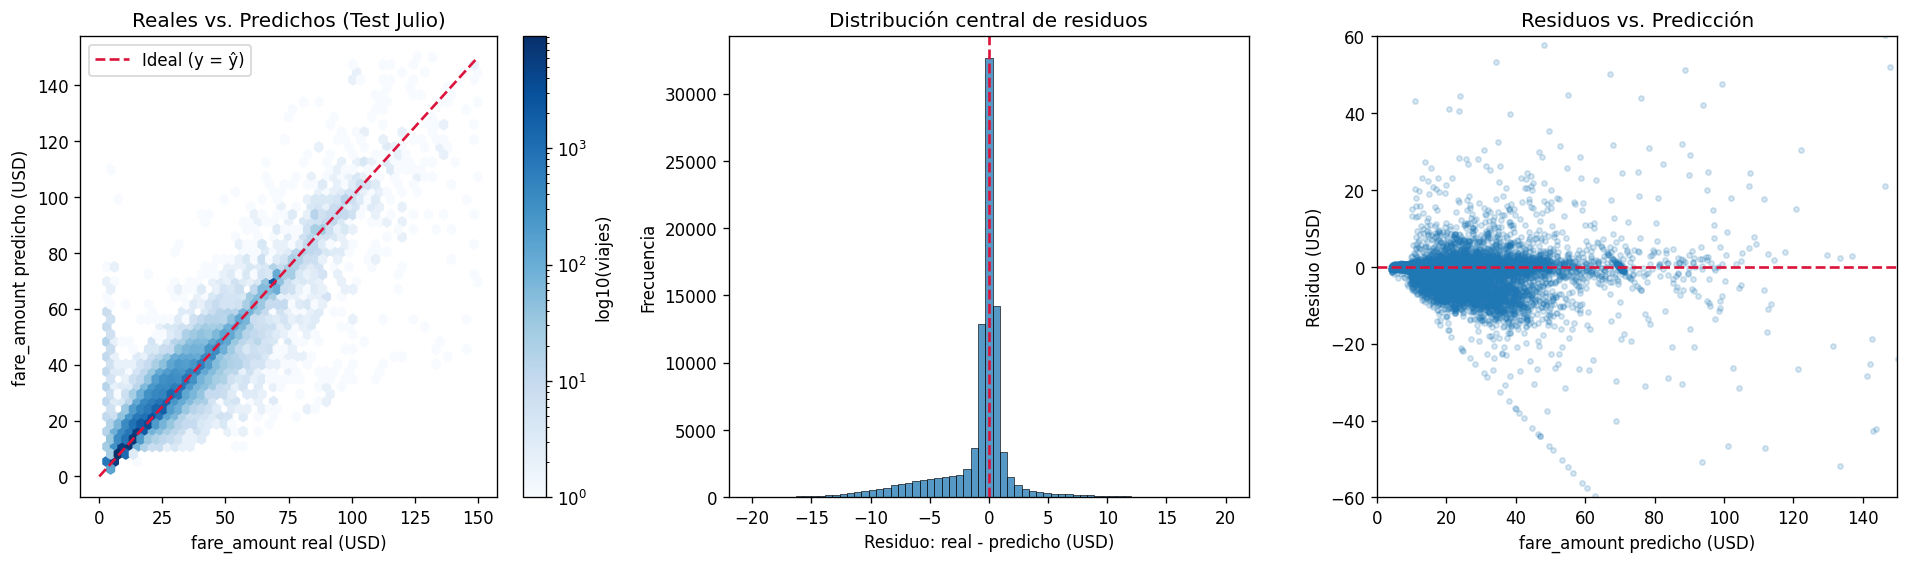

In [ ]:
# ============================================================
# 24.1 Valores reales vs. predichos y análisis de residuos
# ============================================================

residuals = y_test.to_numpy() - pred_test_final

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

hb = axes[0].hexbin(
    y_test, pred_test_final, gridsize=50, cmap="Blues", bins="log", mincnt=1, extent=[0, 150, 0, 150]
)
axes[0].plot([0, 150], [0, 150], color="crimson", linestyle="--", linewidth=1.6, label="Ideal (y = ŷ)")
axes[0].set_xlabel("fare_amount real (USD)")
axes[0].set_ylabel("fare_amount predicho (USD)")
axes[0].set_title("Reales vs. Predichos (Test Julio)")
axes[0].legend(loc="upper left")
plt.colorbar(hb, ax=axes[0], label="log10(viajes)")

res_central = residuals[(residuals >= -20) & (residuals <= 20)]
sns.histplot(res_central, bins=65, ax=axes[1])
axes[1].axvline(0, color="crimson", linestyle="--", linewidth=1.6)
axes[1].set_xlabel("Residuo: real - predicho (USD)")
axes[1].set_ylabel("Frecuencia")
axes[1].set_title("Distribución central de residuos")

sample_i = np.random.default_rng(RANDOM_STATE).choice(len(pred_test_final), size=15_000, replace=False)
axes[2].scatter(pred_test_final[sample_i], residuals[sample_i], alpha=0.18, s=10)
axes[2].axhline(0, color="crimson", linestyle="--", linewidth=1.6)
axes[2].set_xlim(0, 150)
axes[2].set_ylim(-60, 60)
axes[2].set_xlabel("fare_amount predicho (USD)")
axes[2].set_ylabel("Residuo (USD)")
axes[2].set_title("Residuos vs. Predicción")

plt.tight_layout()
plt.show()

La densidad de predicciones se alinea estrechamente sobre la diagonal ideal $y = \hat{y}$, con una concentración especialmente marcada en (70, 70) correspondiente a la tarifa plana del aeropuerto JFK. La distribución de residuos está centrada en 0 USD sin sesgo sistemático global, aunque exhibe heterocedasticidad creciente en tarifas altas (> 40 USD), donde intervienen viajes largos y tarifas especiales.

In [ ]:
# ============================================================
# 24.2 Importancia de variables (Permutation Importance en Test)
# ============================================================

perm_idx = np.random.default_rng(RANDOM_STATE).choice(len(X_test), size=20_000, replace=False)

perm = permutation_importance(
    final_model,
    X_test.iloc[perm_idx],
    y_test.iloc[perm_idx],
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=1
)

imp_df = pd.DataFrame({
    "variable": final_features,
    "incremento_MAE_USD": perm.importances_mean,
    "std_USD": perm.importances_std
}).sort_values("incremento_MAE_USD", ascending=False)

display(imp_df)

plt.figure(figsize=(10, 4.5))
sns.barplot(data=imp_df, x="incremento_MAE_USD", y="variable")
plt.xlabel("Aumento del MAE al permutar la variable (USD)")
plt.ylabel("Variable")
plt.title("Importancia de variables sobre el conjunto de prueba")
plt.tight_layout()
plt.show()

Las tres variables con mayor peso predictivo son **trip_distance** (+6,183 USD de empeoramiento en el **MAE** al desordenarla), **trip_duration_minutes** (+5,194 USD) y **RatecodeID** (+3,110 USD), reflejando con fidelidad las reglas físicas y regulatorias de tarificación. En cuarto lugar aparece **passenger_count** (+0,582 USD), cuyo indicador de faltante asociado identifica a los viajes *Flex Fare*, seguido por las zonas de origen y destino (PULocationID, DOLocationID).

,regimen_tarifario,viajes,porcentaje_%,tarifa_media_USD,MAE_USD,MedAE_USD,RMSE_USD
0,1 - Estándar (Taxímetro),64519,68.964,16.784,0.552,0.331,1.433
6,NaN - Flex Fare (App),24421,26.103,24.591,6.142,4.873,8.946
1,2 - JFK Tarifa Plana ($70),2295,2.453,70.002,0.526,0.198,1.475
5,99 - Desconocido,1418,1.516,20.402,5.509,5.134,6.821
4,5 - Tarifa Negociada,387,0.414,83.639,19.185,10.544,36.057
2,3 - Newark,267,0.285,78.549,3.440,1.836,6.355
3,4 - Nassau / Westchester,248,0.265,109.022,19.069,11.210,28.473


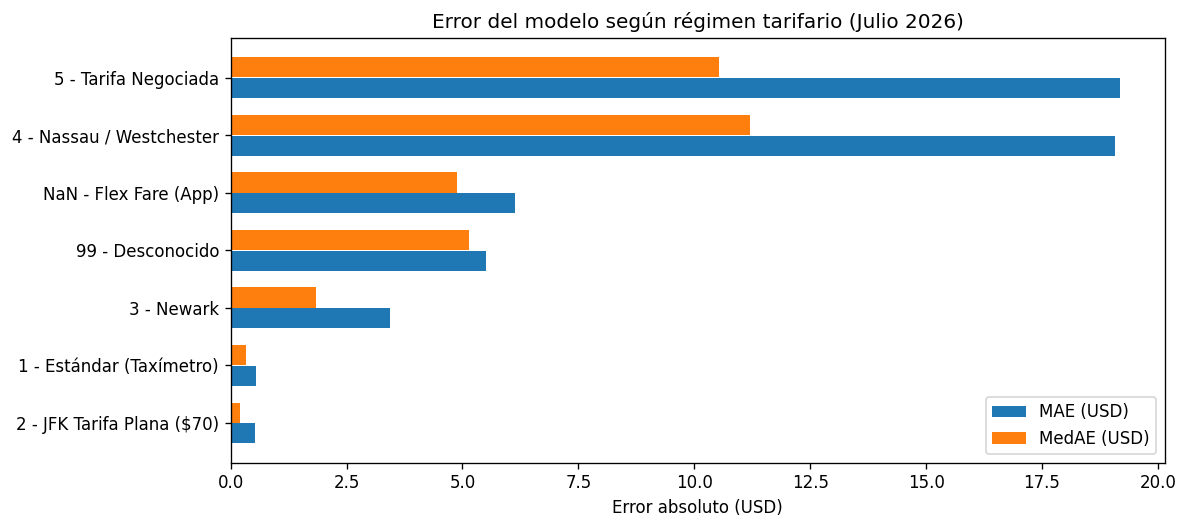


Mayores desvíos individuales en Julio 2026 (candidatos a auditoría):


,tpep_pickup_datetime,regimen,trip_distance,trip_duration_minutes,fare_real,fare_pred,residuo
575209,2026-07-05 15:50:28,5 - Tarifa Negociada,108.610,117.117,500.000,218.599,281.401
610639,2026-07-17 11:45:24,5 - Tarifa Negociada,127.610,194.500,489.000,218.833,270.167
575985,2026-07-05 21:35:03,5 - Tarifa Negociada,3.810,22.417,300.000,48.624,251.376
620954,2026-07-20 13:13:40,NaN - Flex Fare (App),105.810,123.000,366.410,140.696,225.714
610488,2026-07-17 10:31:57,1 - Estándar (Taxímetro),92.100,152.867,346.000,128.607,217.393
571844,2026-07-04 02:48:37,5 - Tarifa Negociada,52.820,72.983,371.000,178.367,192.633
597051,2026-07-13 03:53:31,NaN - Flex Fare (App),12.900,25.350,192.590,48.256,144.334
596990,2026-07-13 01:12:06,5 - Tarifa Negociada,4.350,15.750,180.000,56.126,123.874
619749,2026-07-19 23:54:20,NaN - Flex Fare (App),11.160,23.683,162.000,40.743,121.257
648963,2026-07-29 15:22:38,5 - Tarifa Negociada,56.560,109.817,348.000,227.894,120.106


In [ ]:
# ============================================================
# 24.3 Desempeño por régimen tarifario y detección de casos atípicos
# ============================================================

rate_map = {
    "1": "1 - Estándar (Taxímetro)",
    "2": "2 - JFK Tarifa Plana ($70)",
    "3": "3 - Newark",
    "4": "4 - Nassau / Westchester",
    "5": "5 - Tarifa Negociada",
    "6": "6 - Viaje Grupal",
    "99": "99 - Desconocido",
    "Missing_FlexFare": "NaN - Flex Fare (App)"
}

eval_df = test_df[["tpep_pickup_datetime", "trip_distance", "trip_duration_minutes", "RatecodeID"]].copy()
eval_df["regimen"] = eval_df["RatecodeID"].fillna("Missing_FlexFare").map(lambda x: rate_map.get(x, x))
eval_df["fare_real"] = y_test.to_numpy()
eval_df["fare_pred"] = pred_test_final
eval_df["residuo"] = eval_df["fare_real"] - eval_df["fare_pred"]
eval_df["error_abs"] = np.abs(eval_df["residuo"])

slice_table = []
for reg, grp in eval_df.groupby("regimen"):
    slice_table.append({
        "regimen_tarifario": reg,
        "viajes": len(grp),
        "porcentaje_%": len(grp) / len(eval_df) * 100,
        "tarifa_media_USD": grp["fare_real"].mean(),
        "MAE_USD": grp["error_abs"].mean(),
        "MedAE_USD": grp["error_abs"].median(),
        "RMSE_USD": root_mean_squared_error(grp["fare_real"], grp["fare_pred"])
    })

slice_table_df = pd.DataFrame(slice_table).sort_values("viajes", ascending=False)
display(slice_table_df)

plt.figure(figsize=(10, 4.5))
plot_s = slice_table_df.sort_values("MAE_USD", ascending=True)
y_pos = np.arange(len(plot_s))
plt.barh(y_pos - 0.18, plot_s["MAE_USD"], height=0.35, label="MAE (USD)")
plt.barh(y_pos + 0.18, plot_s["MedAE_USD"], height=0.35, label="MedAE (USD)")
plt.yticks(y_pos, plot_s["regimen_tarifario"])
plt.xlabel("Error absoluto (USD)")
plt.title("Error del modelo según régimen tarifario (Julio 2026)")
plt.legend()
plt.tight_layout()
plt.show()

print("\nMayores desvíos individuales en Julio 2026 (candidatos a auditoría):")
display(
    eval_df.sort_values("error_abs", ascending=False).head(10)[
        ["tpep_pickup_datetime", "regimen", "trip_distance", "trip_duration_minutes", "fare_real", "fare_pred", "residuo"]
    ]
)

El desglose por régimen tarifario permite interpretar con claridad dónde acierta y dónde falla el modelo:

- **Aciertos de alta precisión (>71 % de los viajes):** En **1 - Estándar (Taxímetro)** (64.519 viajes) logra **MAE** = 0,552 USD y **MedAE = 0,331 USD**, y en **2 - JFK Tarifa Plana** (2.295 viajes) logra **MAE** = 0,526 USD y **MedAE = 0,198 USD**.
- **Casos donde el error se incrementa:**
  1. **5 - Tarifa Negociada (MAE = 19,185 USD):** el importe se acuerda libremente entre pasajero y chofer sin fórmula fija de taxímetro.
  2. **4 - Nassau / Westchester (MAE = 19,069 USD):** la normativa duplica la tarifa recién al cruzar el límite de NYC, pero el dataset no incluye la coordenada GPS exacta de dicho cruce.
  3. **NaN - Flex Fare (App) (MAE = 6,142 USD, MedAE = 4,873 USD):** incorpora tarifas dinámicas de oferta/demanda (*surge pricing*) no registradas en las columnas públicas de la TLC.
- **Uso práctico en auditoría:** Los casos con mayor residuo exponen situaciones anómalas concretas (por ejemplo, un viaje de tarifa estándar facturado en 346,00 USD cuando la estimación esperada era 128,61 USD), funcionando como un filtro automático de priorización para auditores.

# 25. Conclusiones de la Entrega Final

Retomando los interrogantes abiertos al cierre de la Pre-entrega (punto **18.9**), los resultados obtenidos permiten concluir:

1. **Algoritmo con mejor desempeño:**
   Entre los cuatro enfoques evaluados dentro de Pipeline con validación cruzada temporal (**DummyRegressor**, **Ridge**, **RandomForestRegressor** y **HistGradientBoostingRegressor**), **HistGradientBoostingRegressor** obtuvo el mejor rendimiento y equilibrio computacional, mejorando significativamente al modelo lineal **Ridge** (**MAE** en Test de **2,220 USD** frente a 3,181 USD, reducción del **30,2 %**) y superando por **81,1 %** a la referencia base (11,772 USD), con un **R² = 0,898** sobre los 93.555 viajes futuros de julio de 2026 y sin evidencia de *overfitting*.

2. **Variables con mayor importancia predictiva:**
   El análisis por permutación confirmó que **trip_distance** (+6,183 USD), **trip_duration_minutes** (+5,194 USD) y **RatecodeID** (+3,110 USD) concentran la capacidad explicativa principal, complementadas por el indicador de ausencia en **passenger_count** (+0,582 USD, asociado a viajes *Flex Fare*) y por las zonas geográficas (**PULocationID** y **DOLocationID**).

3. **Nivel de error y límites del modelo:**
   En operación regulada por taxímetro estándar y tarifa plana JFK (más del 71 % del parque de viajes), el error mediano es de apenas **0,331 USD y 0,198 USD** respectivamente. Sus principales límites aparecen cuando la tarifa depende de información externa no observada en el dataset público: pactos discrecionales (RatecodeID = 5), punto exacto de cruce interjurisdiccional (RatecodeID = 4) y multiplicadores dinámicos de demanda en aplicaciones (*Flex Fare*).

4. **Posibilidades de mejora:**
   - Incorporar la tabla geoespacial oficial (*NYC Taxi Zone Lookup / Shapefiles*) para calcular distancias entre centroides y proporción de recorrido fuera de límites municipales.
   - Integrar variables meteorológicas horarias (lluvia/nieve) e indicadores rezagados de volumen de demanda por zona-hora para modelar con mayor precisión el componente dinámico de *Flex Fare*.
   - Separar en producción un submodelo normativo para viajes de taxímetro y un submodelo específico para viajes *e-hail*.

5. **Utilidad práctica del proyecto:**
   El pipeline desarrollado constituye un **sistema automatizado de auditoría tarifaria post-viaje** capaz de procesar decenas de miles de liquidaciones cerradas en pocos segundos, estimar la tarifa base esperada sin emplear variables contables derivadas y señalar de forma objetiva el pequeño porcentaje de viajes con sobrefacturación, códigos mal asignados o fallas de taxímetro.

6. **Impacto de la calidad de datos frente al algoritmo (*enfoque Data-Centric*):**
   El desarrollo demostró que las decisiones de preparación e ingeniería de datos incidieron tanto como la elección del modelo. En particular, tres ajustes estructurales resultaron determinantes para obtener predicciones realistas y sin sesgo de selección:
   - conservar los **161.533 viajes válidos *Flex Fare* (24,58 %)** tratando sus faltantes dentro del Pipeline en lugar de eliminarlos;
   - codificar **RatecodeID**, **PULocationID** y **DOLocationID** como variables categóricas nominales y no como magnitudes continuas;
   - filtrar errores físicos extremos de sensor (como lecturas de 250.937 millas) mediante reglas de negocio, sin descartar viajes largos legítimos detectados por IQR.

7. **Balance entre complejidad, interpretabilidad y escalabilidad:**
   Si bien **Ridge** ofrece una estructura lineal simple y rápida (10,0 s en validación cruzada, MAE = 3,181 USD), el paso a **HistGradientBoostingRegressor** redujo el error mediano a **la tercera parte** (MedAE de 1,556 USD a **0,519 USD**) y mejoró incluso el tiempo de entrenamiento respecto de **Random Forest** (50,6 s frente a 73,2 s). Esta eficiencia permite escalar el pipeline para auditar el padrón mensual completo (~3,5 millones de viajes) en pocos segundos.

8. **Regla operativa sugerida para la toma de decisiones en Auditoría:**
   Para traducir la predicción del modelo en una herramienta concreta de gestión sin generar falsos positivos, conviene aplicar **umbrales de alerta diferenciados por régimen tarifario**:
   - **Taxímetro estándar (RatecodeID = 1) y Tarifa Plana JFK (RatecodeID = 2):** dado que su error mediano normal es de 0,331 USD y 0,198 USD, marcar para revisión todo viaje con desvío absoluto superior a **5,00 USD** (o mayor al **20 %**).
   - **Viajes por aplicación (*Flex Fare*) o interjurisdiccionales:** aplicar un umbral de tolerancia más amplio (por ejemplo, desvíos mayores a **15,00–20,00 USD**) acorde a su mayor dispersión estructural.

9. **Uso responsable, cobertura geográfica y supervisión humana (*Human-in-the-Loop*):**
   - **Cobertura espacial:** al acotar **OneHotEncoder** a las 40 zonas más frecuentes (concentradas principalmente en Manhattan y aeropuertos), las zonas periféricas quedan agrupadas en la categoría poco frecuente y pueden presentar un error relativo superior.
   - **Supervisión humana:** un residuo elevado constituye una **alerta de auditoría y no una prueba automática de infracción**, ya que puede originarse en desvíos viales imprevistos, cortes de tránsito o errores manuales al registrar el código tarifario. La sanción o ajuste contable requiere siempre validación humana posterior.

10. **Monitoreo y mantenimiento post-despliegue:**
    Para sostener la vigencia del modelo en producción se recomienda implementar tres controles periódicos:
    - monitorear mensualmente la proporción de viajes *Flex Fare* para detectar cambios en la composición operativa (*data drift*);
    - vigilar el MedAE segmentado por RatecodeID como alerta temprana ante eventuales actualizaciones del cuadro tarifario oficial de la NYC TLC (*concept drift*);
    - reentrenar el Pipeline completo con ventana móvil trimestral o semestral.

# 26. ¿Este modelo funciona con los datos que realmente voy a tener cuando lo use?

La respuesta depende directamente del **momento operativo** en que se utilice el modelo:

1. **En el escenario definido para este proyecto (Auditoría posterior o control de liquidaciones de viajes cerrados): SÍ funciona con los datos reales que se tendrán al usarlo.**
   - Cuando el viaje ya concluyó y se audita el registro operativo (como se simuló de forma realista evaluando sobre todo el mes futuro de **julio de 2026**), las nueve variables que consume el Pipeline (**trip_distance**, **trip_duration_minutes**, **RatecodeID**, **PULocationID**, **DOLocationID**, **passenger_count**, **pickup_hour**, **pickup_weekday**, **is_weekend**) **están efectivamente disponibles** sin depender de **total_amount**, recargos ni **payment_type**.
   - Además, el Pipeline fue diseñado para resistir las particularidades reales que llegan en esos datos: **valores faltantes estructurales** en el ~25 % de viajes *Flex Fare* (**SimpleImputer** con indicador y categoría **"Missing_FlexFare"**) y **zonas geográficas poco frecuentes** (**OneHotEncoder** con **handle_unknown="infrequent_if_exist"**).
   - **Condición operativa necesaria:** mantener antes de **final_model.predict()** la etapa de reglas de consistencia física (distancia, duración y velocidad media dentro de rangos posibles) para que los registros con fallas graves de GPS o taxímetro (ej. 0 millas o 250.000 millas) se deriven directamente como errores técnicos de medición.

2. **Si se quisiera usar antes de iniciar el viaje (por ejemplo, como cotizador previo en una app de pasajeros): NO funcionaría directamente con este entrenamiento.**
   - Antes de realizar el viaje **no existen todavía** la duración real insumida en el tráfico (**trip_duration_minutes**), la distancia final medida por el odómetro ni siempre el **RatecodeID** definitivo. Reemplazarlos en producción por estimaciones previas de un mapa de ruteo introduciría un desfasaje entre entrenamiento y uso real (*train-serving skew*). Para ese objetivo distinto habría que reentrenar un modelo excluyendo las variables post-viaje y utilizando únicamente predictores conocidos *ex-ante*.

3. **Mantenimiento en el tiempo:**
   - Aun en auditoría post-viaje, si la NYC TLC actualiza su cuadro tarifario oficial o cambia sustancialmente la proporción de viajes con tarifa dinámica (*Flex Fare*), el rendimiento se degradaría (*concept/data drift*), por lo que en uso real debe monitorearse mensualmente el **MAE** por **RatecodeID** y reentrenarse periódicamente.

# 27. Anexo final

### Link al dataset utilizado
- **NYC Taxi & Limousine Commission (TLC) — Trip Record Data (archivos mensuales Yellow Taxi 2026 en formato Parquet):**  
  https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page
- **Diccionario oficial de variables — Yellow Taxi Trip Records (NYC TLC):**  
  https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf
- **Cuadro tarifario vigente de NYC Yellow Taxi (TLC Rates of Fare):**  
  https://www.nyc.gov/site/tlc/passengers/taxi-fare.page

### Aclaraciones
1. **Continuidad con la Pre-entrega:** Las secciones **1 a 18** conservan íntegramente el desarrollo exploratorio y diagnóstico generado en la instancia de Pre-entrega; a partir de la sección **19** se integran y responden las observaciones que me realizó Ariel en la evaluación del anteproyecto y se desarrolla el ciclo completo de modelado, validación cruzada temporal, optimización y evaluación final.
2. **Muestreo reproducible:** Dado que los siete archivos completos totalizan **26.366.639 registros**, se mantuvo la muestra aleatoria estratificada de **100.000 viajes por mes** (700.000 observaciones totales) con semilla fija **RANDOM_STATE = 42**, asegurando representatividad mensual completa y tiempos de ejecución reproducibles tanto en entorno local como en Google Colab.